# Can a language model write a random forest and an LSTM by hand?

## A trained model is a file of numbers

When a lender screens applications or a shop plans tomorrow's staffing, the prediction usually comes from a trained
model. This notebook works with two common kinds.

A random forest sorts cases into classes. It is a set of decision trees, and each tree is a flowchart of yes-or-no
questions about the case: "is feature 3 above 5.0?", then, depending on the answer, another question, until the path
ends at a leaf. The leaf holds a vote for each class. The forest asks every tree, averages the votes and picks the
class with the most.

An LSTM (long short-term memory network) is a small neural network for sequences. It reads a history one day at a
time, keeps a few numbers in memory as it goes, and at the end writes a forecast. What it keeps, what it forgets and
how it turns memory into a forecast are all set by its weights, a few hundred numbers fed into a fixed formula.

Either way, the finished model is data. A forest is a list of questions, thresholds and leaf votes. An LSTM is a list
of weights. Normally nobody writes these by hand. A training program reads labelled examples and searches for numbers
that fit them: it picks the question that best separates the classes in the examples, then the next one, or it
nudges every weight a little at a time to reduce the forecast error.

## Asking a language model to write the file

Language models can read a few hundred rows of a table and describe the pattern in them. This notebook asks for
more than a description. A model receives the same labelled examples a training program would get, together with
the exact code that will run its answer, and has to write the whole file itself: every question and threshold of the
forest, or every weight of the LSTM. It has no tools, so it cannot run code, fit anything or check its numbers. A
separate tester loads the file unchanged and scores it on data the model never saw.

There are three reasons to run this test. The first is that it shows whether a model can turn data into a working
program without executing anything, which is hard to see from a chat answer. The second is that a written model can
in principle be better than a trained one. A training program does not know what kind of rule produced the data; it
makes the locally best cut at each step and fits whatever the examples show, noise included. A reader who recognises
the rule can write it down directly. The third is practical: a written model is readable, so a person can check what
it does, but only if the file loads and the structure inside matches the rule.

## An illustrative example: a circle drawn with straight cuts

This small example is made up to explain the idea; the measured tasks come later.

Picture points scattered over a 10 by 10 square. A point is labelled "inside" when it lies within a circle of radius
3 around the centre (5, 5), and "outside" otherwise. A decision tree cannot ask "are you inside the circle?". It can
only ask about one coordinate at a time, such as "is x0 at most 2.5?", so every region it describes is a rectangle.
To describe a circle it has to build a staircase: a central square whose corners are trimmed by further questions,
each level of questions making the steps finer. With up to eight questions on each path from the top of the tree to a
leaf, the staircase can follow a circle closely.

A person writing this tree by hand would first look at the labelled points, notice that the "inside" points form a
disc around (5, 5), and then place the cuts from the geometry of a circle, not from the individual points.

Now add one complication: one label in ten is wrong. A few "inside" labels appear in the corners, and a few points
near the centre are marked "outside". A training program that sees only the examples cannot tell a wrong label from a
small real pocket of the class, so it may carve a little box around a stray point, or misplace a step because several
wrong labels happen to sit together. The person who has recognised the circle ignores those points. With few examples
and noisy labels, finding the rule and fitting the examples can give different models, and hidden test data shows
which one generalises.

## The same idea for a forecaster

A second made-up example. A shop sells more on Saturdays than on Mondays, so a reasonable forecast for tomorrow starts
from the sales on the same weekday last week. An LSTM reads the last 28 days one at a time, oldest first. To use the
value from 7 days before the forecast, it has to catch that one number as it passes, hold it in memory and ignore the
six days that follow.

Weights can do this. Because the tester always feeds exactly 28 days, a memory cell can count the steps and open its
input only at the step that holds the value from a week ago. Another arrangement passes values along a chain of memory
cells, one step per day, like a queue. A training program is never told to build either; it finds whatever arrangement
reduces the error on the examples, and with a few hundred training days it may settle on a rougher one.

The complication here is promotions. A promotion lifts sales on its day and is followed by a dip the next day. The
forecaster is told whether tomorrow is a promotion day, so a written LSTM has to add the lift when that flag is on
and subtract the dip when yesterday's flag was on, on top of the weekly pattern.

## Two ways to get the numbers

The comparison in this notebook is between two ways of producing the same kind of model.

- Training: a program starts from random or empty values and adjusts them step by step to fit the labelled examples.
  It is cheap and repeatable, never breaks the file format, and knows nothing about what rule produced the data.
- Writing: a language model reads the examples, works out what rule it thinks produced them, and writes the
  thresholds or weights that compute that rule. It may find the real rule and beat training, misread the data, or
  return a file that does not load.

Both are held to the same limits. A written forest may use at most 20 trees with at most 8 questions on any path, and
the trained forest gets the same limits. A written LSTM has 8 memory units and 393 weights, and the trained LSTM has
the same shape.

## The question

Can a language model with no tools write a working random forest classifier and a working LSTM forecaster directly,
as parameter files, from a small labelled sample? How does the written model compare with the same kind of model
trained in the usual way, and with simpler rules of thumb?

## Study summary

Eight language models each wrote three random forests for each of four classification tasks and three LSTMs for
each of two forecasting tasks, 144 requests in all. The models were three Claude models, GPT-6.1 Sol, Muse Wonder
Full and three large open-weight models. Every file was loaded unchanged and scored on 5,000 hidden rows or 140 hidden
days. It was compared with the same kinds of model trained by scikit-learn and gradient descent on the same visible
data, and with the rule that generated the data.

When the labels follow a short rule, the best writers find the rule and write it down, and then they beat training by
a wide margin. GPT-6.1 Sol did so in all 9 of its rules-task forests, scoring 92.0% to 92.4% on hidden rows against a
ceiling of 92.6%. With only 200 visible rows, the trained forest with the same limits scored 54.2% and gradient
boosting 75.4%. Claude Opus 5.5 scored 90% or more in 5 of its 9 rules-task forests, Muse Wonder Full in 4 and Claude
Fable 5.1 in 3; their other forests scored 26% to 90%, most of them after dropping or misplacing one of the three
rules. Claude Sonnet 5.5, Kimi K3.1 Pro and
DeepSeek V4.1 Flash wrote readable forests that scored 33% to 60%. GLM 5.3 spent its whole 128,000-token allowance
reasoning in 15 of 18 requests and returned nothing.

When the labels come from a smooth function with no short description, writing has no advantage. The best written
forests (Sol, median 71.1%) matched the trained forest with the same limits (69.4%) and fell short of gradient
boosting (74.1%).

The best written LSTMs work. On the weekly task, Opus, Fable and Sol scored RMSE 2.60 to 3.02, better than the same
network trained by gradient descent (3.87) but not as good as a plain linear model on the same inputs (2.47). They
average the same weekday over the last three or four weeks and add 15 to 18 for a promotion, close to the
generator's +15. None of the written LSTMs picked up the 30-day pay cycle in the second task: none puts more than 0.05
of weight on the value 30 days back, and every one misses the first four days of the month by 7 to 12.6.

In the original situation, this means a model can hand over a working, readable forest that beats anything trained on
a small sample, but only when the data follows a rule it can see, and not every time. A cheap check makes it usable:
because nothing is fitted, a written file's score on the visible rows predicts its hidden score (correlation 0.97), so
asking for three files and keeping the best on the visible data recovered a ceiling forest from Opus, Fable, Muse and
Sol on most rules tasks. The main caveat is that every task here is synthetic and was built to have a recognisable
rule; three requests per model per task show the spread but do not pin down any model's rate of success.

## Contents

1. [Setup and configuration](#1.-Setup-and-configuration)
2. [The data](#2.-The-data)
3. [The request and the models](#3.-The-request-and-the-models)
4. [Scoring and references](#4.-Scoring-and-references)
5. [Results: written forests](#5.-Results:-written-forests)
6. [Results: written LSTMs](#6.-Results:-written-LSTMs)
7. [What the written models encode](#7.-What-the-written-models-encode)
8. [Unreadable replies and wrong answers](#8.-Unreadable-replies-and-wrong-answers)
9. [Effort, time and cost](#9.-Effort,-time-and-cost)
10. [How the study got here](#10.-How-the-study-got-here)
11. [Limitations](#11.-Limitations)
12. [How to reproduce](#12.-How-to-reproduce)
13. [Future work and further reading](#13.-Future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart LR
    gen["Generators in code<br/>4 forest tasks, 2 sales series<br/>fixed seeds"] --> prompt["One prompt per task<br/>labelled rows or sales history<br/>+ exact inference code"]
    prompt --> calls["8 models x 6 tasks x 3 requests<br/>144 single-turn calls, no tools<br/>claude -p, codex exec, muse exec, OpenRouter"]
    calls --> parse["Parser<br/>a loadable file, or one of<br/>5 kinds of unreadable reply"]
    parse --> run["Tester runs the file unchanged<br/>5,000 hidden rows or<br/>140 hidden days"]
    run --> score["Accuracy or RMSE<br/>by rule, by day type,<br/>what the file reads"]
    gen --> refs["References fitted to the<br/>same visible data<br/>trained models and rules of thumb"]
    refs --> score
```

Each request is a single call with no conversation history, so there is no chain of model calls to draw. The only
repeated call is a retry after a transport failure (a crashed command line or an HTTP error), at most three attempts,
all logged. One example travels like this: the 600-row rules task becomes a 25,421-character prompt; Claude Fable 5.1
returns a 175-node, three-tree forest as JSON; the parser checks it against the prompt's rules; the tester runs it on
5,000 hidden rows and counts 4,573 correct (91.5%), which section 4 traces for one row.

## 1. Setup and configuration

The code below is self-contained. It defines the tasks, the prompts, the four ways of calling models, the cache and
the scoring. By default nothing is sent to any model: every reply is read from `data/responses/`. `MODELS`, `TASKS`
and `N_REPEATS` are the size knobs; setting the environment variable `NB45_FRESH=1` allows fresh, paid calls for
anything not yet cached.

The harness, scoring, data-preview and sensitivity-check code were written by Claude Opus 5.5, starting from the
pilot's script. The analysis tables and figures in sections 5 to 9 were written by GPT-6.1 Terra through `codex exec`
from a specification, then reviewed, formatted and adjusted by Claude.

In [1]:
import datetime as dt
import hashlib
import json
import os
import shutil
import subprocess
import threading
import time
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "4")   # scikit-learn stalls with one thread per core on this machine
import numpy as np
import requests

NOTEBOOK = "45-handwritten-forest-lstm"
ROOT = Path.cwd()
DATA = ROOT / "data"
RESPONSES = DATA / "responses"
FIGURES = ROOT / "figures"
for folder in (DATA, RESPONSES, FIGURES):
    folder.mkdir(exist_ok=True)

# Size knobs. Every answer used in this notebook is cached in data/responses, so a re-run replays them for free.
# Fresh calls happen only when NB45_FRESH=1 is set in the environment; they cost money.
MODELS = ["opus", "fable", "sonnet", "sol", "muse", "kimi", "glm", "deepseek"]
TASKS = ["rules-600", "rules-200", "rules-1500", "smooth-600", "weekly", "two-cycles"]
N_REPEATS = 3
ALLOW_FRESH_CALLS = os.environ.get("NB45_FRESH") == "1"

In [2]:
MODEL_INFO = {
    "opus": dict(label="Claude Opus 5.5", vendor="claude", model="claude-opus-5-5"),
    "fable": dict(label="Claude Fable 5.1", vendor="claude", model="claude-fable-5-1"),
    "sonnet": dict(label="Claude Sonnet 5.5", vendor="claude", model="claude-sonnet-5-5"),
    "sol": dict(label="GPT-6.1 Sol", vendor="codex", model="gpt-6.1-sol"),
    "muse": dict(label="Muse Wonder Full", vendor="muse", model="muse-wonder-full-1.0"),
    "kimi": dict(label="Kimi K3.1 Pro", vendor="openrouter", model="moonshotai/kimi-k3.1-pro",
                 permaslug="moonshotai/kimi-k3.1-pro-20261023", provider="moonshotai/mxfp4"),
    "glm": dict(label="GLM 5.3", vendor="openrouter", model="z-ai/glm-5.3",
                permaslug="z-ai/glm-5.3-20260816", provider="z-ai/fp8"),
    "deepseek": dict(label="DeepSeek V4.1 Flash", vendor="openrouter", model="deepseek/deepseek-v4.1-flash-1017",
                     permaslug="deepseek/deepseek-v4.1-flash-20261017", provider="deepseek"),
}
EFFORT = "high"              # the same reasoning setting for every model
MAX_OUTPUT_TOKENS = 128000   # output allowance, thinking included, where the interface takes one
CALL_TIMEOUT_S = 90 * 60     # a call still running after 90 minutes is stopped and counted as a timeout

## 2. The data

All data is synthetic, generated in code from fixed seeds on 9 November 2026. The 600-row rules task and the weekly
sales task are the same sets the pilot generated on 5 November. No model can have seen any of it in training, so the
usual check on training cutoffs and item dates does not apply, and the exact generating rule is known, so every score
can be compared with the best possible score.

### The forest tasks

Each row has eight features. x0 to x6 are numbers between 0 and 10 with two decimals. x7 is a category code 0, 1, 2
or 3; the prompt says the codes are names, so their order means nothing. The label is one of four classes.

In the three rules tasks the label comes from three rules, checked in this order so that a later rule overrides an
earlier one:

| Class | Name used here | Rule |
|---|---|---|
| 1 | exactly-one | exactly one of x3 and x4 is above 5 |
| 2 | category | x7 is code 2 and x2 is above 4 |
| 3 | circle | the point (x0, x1) lies within 2.83 (the square root of 8) of (5, 5) |
| 0 | rest | none of the above |

x5 and x6 are never used. After the rule is applied, 10% of rows get a class drawn at random, which can be the same
class, so 7.4% of the hidden labels differ from the rule and the rule itself scores 92.6% on the hidden rows. No
classifier can expect to do better, so 92.6% is the ceiling.

| Task | Visible rows | Hidden rows | What changes |
|---|---|---|---|
| Rules, 200 rows | 200 (the first 200 of the 600) | 5,000 | less data |
| Rules, 600 rows | 600 | 5,000 | the pilot task |
| Rules, 1,500 rows | 1,500 (the 600 plus 900 more) | 5,000 | more data |
| Smooth, 600 rows | 600 | 5,000 | labels from a smooth random function |

The three rules tasks share the same 5,000 hidden rows and their visible rows are nested, so differences between them
come only from the amount of data.

The smooth task keeps the same features and the same 10% noise but replaces the rules with a function that has no
short description. Each class gets a score made of eight random sine waves over x0 to x3 plus a shift for each
category code, and the label is the class with the highest score. The boundaries between classes are curved and
irregular, and x4, x5 and x6 are unused. Its noise-free labels also score 92.6% on its hidden rows. This task asks
what happens when there is no rule to recognise, only a shape to approximate, which is the situation a training
program is built for.

In [3]:
N_FEAT, N_CLASS, MAX_TREES, MAX_SPLITS, MAX_NODES = 8, 4, 20, 8, 511
N_HIDDEN_ROWS = 5000
RF_CODE = '''import numpy as np
def tree_predict(tree, x):
    # tree["nodes"] is a list; node 0 is the root.
    # An internal node is {"id":i,"feature":f,"threshold":t,"left":j,"right":k}; go left when x[f] <= t.
    # A leaf is {"id":i,"leaf":[p0,p1,p2,p3]}: class scores (non-negative, need not sum to 1).
    nodes = {n["id"]: n for n in tree["nodes"]}
    n = nodes[0]
    while "leaf" not in n:
        n = nodes[n["left"]] if x[n["feature"]] <= n["threshold"] else nodes[n["right"]]
    return np.asarray(n["leaf"], dtype=float)
def forest_predict(forest, x):
    # Average the leaf vectors of all trees; the predicted class is the argmax (ties: lowest class).
    return int(np.argmax(np.mean([tree_predict(t, x) for t in forest["trees"]], axis=0)))
'''
RULE_NAMES = ["rest", "exactly-one", "category", "circle"]


def rules_labels(X):
    """The generating rule of the rules tasks, applied in order so later rules win."""
    y = np.zeros(len(X), dtype=int)
    y[(X[:, 3] > 5) ^ (X[:, 4] > 5)] = 1                       # exactly one of x3 and x4 above 5
    y[(X[:, 7] == 2) & (X[:, 2] > 4)] = 2                      # category code 2 and x2 above 4
    y[(X[:, 0] - 5) ** 2 + (X[:, 1] - 5) ** 2 < 8] = 3         # inside a circle around (5, 5)
    return y


def smooth_scorer(seed=20261109, n_waves=8, scale=1.5):
    """Four class scores built from random smooth waves over x0..x3 plus a per-category shift."""
    r = np.random.default_rng(seed)
    W = r.normal(0, scale, size=(n_waves, 4)) / 10
    phase = r.uniform(0, 2 * np.pi, n_waves)
    A = r.normal(0, 1, size=(N_CLASS, n_waves))
    C = r.normal(0, 0.6, size=(N_CLASS, 4))

    def scores(X):
        return np.sin(X[:, :4] @ W.T + phase) @ A.T + C[:, X[:, 7].astype(int)].T

    grid = np.random.default_rng(0).uniform(0, 10, size=(20000, N_FEAT))
    grid[:, 7] = np.random.default_rng(1).integers(0, 4, 20000)
    S, bias = scores(grid), np.zeros(N_CLASS)
    for _ in range(300):                                        # shift class scores until the classes are about equal
        share = np.bincount(np.argmax(S + bias, 1), minlength=N_CLASS) / len(S)
        bias -= 0.5 * (share - 0.25)
    return lambda X: np.argmax(scores(X) + bias, 1)


smooth_labels = smooth_scorer()


def make_rows(rng, n, labeller):
    X = rng.uniform(0, 10, size=(n, N_FEAT)).round(2)
    X[:, 7] = rng.integers(0, 4, n)
    clean = labeller(X)
    y = clean.copy()
    flip = rng.random(n) < 0.10                                  # 10% of rows get a random class (it can be the same one)
    y[flip] = rng.integers(0, N_CLASS, flip.sum())
    return X, y, clean


def forest_task(name):
    """Visible rows, hidden rows and noise-free hidden labels. The 200-, 600- and 1,500-row rules tasks are nested
    samples from one source and share the same 5,000 hidden rows."""
    if name.startswith("rules"):
        rng = np.random.default_rng(20261106)
        Xa, ya, _ = make_rows(rng, 600, rules_labels)
        Xt, yt, ct = make_rows(rng, N_HIDDEN_ROWS, rules_labels)
        Xb, yb, _ = make_rows(np.random.default_rng(20261108), 900, rules_labels)
        n = int(name.split("-")[1])
        Xv, yv = (Xa[:n], ya[:n]) if n <= 600 else (np.r_[Xa, Xb], np.r_[ya, yb])
        return dict(task=name, Xv=Xv, yv=yv, Xt=Xt, yt=yt, clean=ct, labeller=rules_labels)
    rng = np.random.default_rng(20261110)
    Xv, yv, _ = make_rows(rng, 600, smooth_labels)
    Xt, yt, ct = make_rows(rng, N_HIDDEN_ROWS, smooth_labels)
    return dict(task=name, Xv=Xv, yv=yv, Xt=Xt, yt=yt, clean=ct, labeller=smooth_labels)


def forest_prompt(Xv, yv):
    rows = "\n".join(",".join(f"{v:.2f}" for v in x[:7]) + f",{int(x[7])},{c}" for x, c in zip(Xv, yv))
    return f'''You are the sole author of a random forest classifier. You have NO tools, code execution,
calculator, files, web or other agents. Reason internally. The tester loads your JSON unchanged and only
runs the inference code below. It will not train, prune, repair or choose anything.

TASK: predict a class 0, 1, 2 or 3 from eight features. x0..x6 are numbers between 0 and 10. x7 is a
category code 0, 1, 2 or 3; the codes are names, so their order means nothing. Not every feature need
matter, and the classes need not follow axis-aligned boundaries. Labels may be noisy. The {len(Xv)} labelled rows
below are the ONLY data you receive. You are scored by accuracy on {N_HIDDEN_ROWS:,} hidden rows from the same source.

MODEL LIMITS: at most {MAX_TREES} trees. In each tree, a path from the root to a leaf passes through at most
{MAX_SPLITS} internal (split) nodes, and the tree has at most {MAX_NODES} nodes. Feature indices 0..7.

EXACT INFERENCE CODE (read, do not execute):
{RF_CODE}
RETURN ONLY {{"trees":[{{"nodes":[...]}}, ...]}} as valid JSON, no prose or Markdown. Every node needs an
integer "id" unique within its tree; node 0 is the root; every "left"/"right" id must exist in that tree;
every leaf has exactly 4 non-negative numbers.

LABELLED ROWS (x0,x1,x2,x3,x4,x5,x6,x7,label):
{rows}
END ROWS. Return only the JSON forest.'''

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

d600 = forest_task("rules-600")
cols = [f"x{i}" for i in range(N_FEAT)]
first = pd.DataFrame(d600["Xv"][:8], columns=cols).assign(x7=lambda f: f.x7.astype(int), label=d600["yv"][:8],
                                                            rule=[RULE_NAMES[c] for c in rules_labels(d600["Xv"][:8])])
print("First eight visible rows of the 600-row rules task (label as given, rule = what the generating rule says):")
print(first.to_string(index=False))

shares = []
for task in ["rules-200", "rules-600", "rules-1500", "smooth-600"]:
    d = forest_task(task)
    shares.append(dict(task=task, visible_rows=len(d["yv"]), **{f"class {c}": int((d["yv"] == c).sum()) for c in range(N_CLASS)},
                       labels_that_differ_from_rule=f"{np.mean(d['labeller'](d['Xv']) != d['yv']):.1%}",
                       rule_accuracy_hidden=f"{np.mean(d['clean'] == d['yt']):.1%}"))
print("\nClass counts in the visible rows and the noise in each task:")
print(pd.DataFrame(shares).to_string(index=False))

First eight visible rows of the 600-row rules task (label as given, rule = what the generating rule says):
  x0   x1    x2   x3   x4   x5   x6  x7  label        rule
0.86 6.22  2.46 6.03 7.73 5.46 0.92   3      0        rest
5.98 6.26  5.26 3.85 0.18 5.54 7.94   3      3      circle
3.20 5.81  9.37 6.38 8.56 8.38 3.36   3      3      circle
3.12 0.53  1.33 3.66 7.31 6.76 8.35   0      1 exactly-one
0.66 3.51  5.27 6.45 1.23 7.87 1.24   2      2    category
8.87 5.63  1.73 9.35 5.13 3.96 0.85   2      0        rest
7.48 9.88 10.00 3.77 6.32 6.66 7.77   3      3 exactly-one
9.92 2.04  4.65 9.93 7.75 9.71 2.79   3      0        rest

Class counts in the visible rows and the noise in each task:
      task  visible_rows  class 0  class 1  class 2  class 3 labels_that_differ_from_rule rule_accuracy_hidden
 rules-200           200       50       71       31       48                         8.0%                92.6%
 rules-600           600      169      193       88      150                  

The first eight rows show what a model receives. In the fifth row the label is 2 (category): x7 is code 2 and x2 is
5.27, above 4. The sixth row also has code 2, but x2 is only 1.73, so the category rule does not apply; x3 and x4 are
both above 5, so exactly-one does not apply either, and the label is 0. The seventh row shows the noise: its label is
3 (circle), but the point (7.48, 9.88) is far outside the circle, and the rule says exactly-one (x3 = 3.77 is below 5,
x4 = 6.32 above). In the 600 visible rows, 8.7% of labels disagree with the rule like this, about one in twelve. The
class counts are uneven because the circle covers about a quarter of the square and the category rule needs one code
out of four. With 200 rows there are only 31 rows of the category class to learn from.

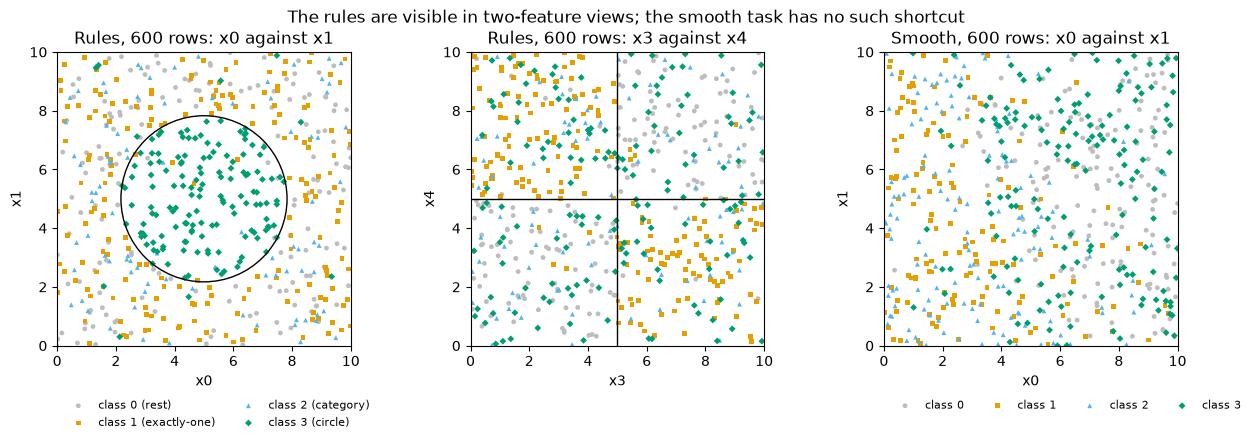

In [5]:
CLASS_COLOURS = ["#bdbdbd", "#e69f00", "#56b4e9", "#009e73"]
CLASS_MARKERS = ["o", "s", "^", "D"]


def plot_forest_data():
    dsm = forest_task("smooth-600")
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
    X, y = d600["Xv"], d600["yv"]
    panels = [(axes[0], X[:, 0], X[:, 1], y, "x0", "x1", "Rules, 600 rows: x0 against x1"),
              (axes[1], X[:, 3], X[:, 4], y, "x3", "x4", "Rules, 600 rows: x3 against x4"),
              (axes[2], dsm["Xv"][:, 0], dsm["Xv"][:, 1], dsm["yv"], "x0", "x1", "Smooth, 600 rows: x0 against x1")]
    for ax, a, b, lab, xl, yl, title in panels:
        for c in range(N_CLASS):
            m = lab == c
            ax.scatter(a[m], b[m], s=12, c=CLASS_COLOURS[c], marker=CLASS_MARKERS[c], edgecolors="none",
                       label=f"class {c} ({RULE_NAMES[c]})" if ax is axes[0] else f"class {c}")
        ax.set(xlabel=xl, ylabel=yl, title=title, xlim=(0, 10), ylim=(0, 10), aspect="equal")
    axes[0].add_patch(plt.Circle((5, 5), np.sqrt(8), fill=False, color="black", lw=1))
    axes[1].axvline(5, color="black", lw=1)
    axes[1].axhline(5, color="black", lw=1)
    axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2, fontsize=8, frameon=False)
    axes[2].legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=4, fontsize=8, frameon=False)
    fig.suptitle("The rules are visible in two-feature views; the smooth task has no such shortcut", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIGURES / "forest_data.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_forest_data()

The left panel plots the 600 visible rows by x0 and x1 with the true circle drawn on. The circle class (green
diamonds) fills the disc, with a few stray labels of other classes inside it and a few green points outside: that is
the 10% noise. The middle panel plots x3 against x4. The exactly-one class (orange squares) sits in the top-left and
bottom-right quarters, where one feature is above 5 and the other below, but it is mixed with circle and category
points, because those rules override it. The right panel is the smooth task: the classes form broad irregular bands
with no single two-feature view that separates them. A reader who looks at the left two panels can see the rules; no
such view exists for the smooth task.

In [6]:
H, IN = 8, 2
N_DAYS, N_VIS = 700, 560
WEEK = np.array([-6.0, -3.0, -2.0, 0.0, 4.0, 11.0, -4.0])
MONTH = np.zeros(30)
MONTH[:4] = [10.0, 6.0, 3.0, 1.0]                                # payday at the start of each 30-day month
MONTH[24:] = -3.0                                                # and a quieter last week
MONTH -= MONTH.mean()
LSTM_TASKS = {"weekly": dict(seed=20261106, window=28, monthly=False),
              "two-cycles": dict(seed=20261108, window=35, monthly=True)}
SHAPES = {"W_ih": (4 * H, IN), "W_hh": (4 * H, H), "b_ih": (4 * H,), "b_hh": (4 * H,), "W_out": (1, H), "b_out": (1,)}
N_LSTM = sum(int(np.prod(s)) for s in SHAPES.values())


def lstm_code(window):
    return f'''import numpy as np
H = {H}   # hidden units; input size 2
def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))
def lstm_predict(inputs, W_ih, W_hh, b_ih, b_hh, W_out, b_out):
    # inputs: {window} rows, oldest first. Row k is [normalise(value on day s), promotion flag on day s+1]
    # for s = t-{window} .. t-1, where t is the day being forecast. So the LAST row holds the latest known
    # value (day t-1) and the promotion flag (0 or 1) of day t itself.
    # Gate order in the 4H rows: input, forget, cell, output.
    # W_ih [4H,2], W_hh [4H,H], b_ih [4H], b_hh [4H], W_out [1,H], b_out [1].
    h = np.zeros(H); c = np.zeros(H)
    for x in inputs:
        z = W_ih @ x + W_hh @ h + b_ih + b_hh
        i, f, g, o = sigmoid(z[0:H]), sigmoid(z[H:2*H]), np.tanh(z[2*H:3*H]), sigmoid(z[3*H:4*H])
        c = f * c + i * g
        h = o * np.tanh(c)
    return float(W_out[0] @ h + b_out[0])   # predicted normalised value of day t
def normalise(y): return (y - 100.0) / 20.0
def denormalise(z): return 20.0 * z + 100.0
'''


def lstm_task(name):
    """Daily sales: trend, weekly cycle, promotions (+15 on the day, -6 the next day), AR(1) noise, and for
    two-cycles a 30-day payday cycle. det is the noise-free part, used only by the true-formula reference."""
    spec = LSTM_TASKS[name]
    rng = np.random.default_rng(spec["seed"])
    t = np.arange(N_DAYS)
    promo = (rng.random(N_DAYS) < 0.12).astype(int)
    noise = np.zeros(N_DAYS)
    for k in range(1, N_DAYS):
        noise[k] = 0.6 * noise[k - 1] + rng.normal(0, 2.0)
    det = 100 + 0.03 * t + WEEK[t % 7] + 15 * promo - 6 * np.r_[0, promo[:-1]]
    if spec["monthly"]:
        det = det + MONTH[t % 30]
    return dict(task=name, y=(det + noise).round(2), promo=promo, det=det, window=spec["window"])


def lstm_prompt(y, promo, window):
    rows = "\n".join(f"{k},{y[k]:.2f},{promo[k]}" for k in range(N_VIS))
    return f'''You are the sole author of the weights of a small LSTM forecaster. You have NO tools, code execution,
calculator, files, web or other agents. Reason internally. The tester loads your numbers unchanged and only
runs the code below. It will not train, fit, repair or choose anything.

TASK: forecast tomorrow's sales of a shop from its recent history. Promotions are planned in advance, so the
promotion flag of the day being forecast is known and is part of the input. For each hidden day t, the tester
builds the {window} input rows from the TRUE past values and the promotion flags, runs the LSTM from a zero state
and compares your prediction with the true value of day t. You receive days 0..{N_VIS - 1} below; you are scored
on days {N_VIS}..{N_DAYS - 1} ({N_DAYS - N_VIS} forecasts) by root mean squared error on the original scale.

ARCHITECTURE: one LSTM layer, input size {IN}, hidden size {H}, then a linear output. {N_LSTM} parameters.

EXACT CODE (read, do not execute):
{lstm_code(window)}
RETURN ONLY one JSON object with these keys and nested lists of finite numbers in exactly these shapes:
"W_ih": 32 rows of 2, "W_hh": 32 rows of 8, "b_ih": 32 numbers, "b_hh": 32 numbers, "W_out": 1 row of 8,
"b_out": 1 number in a list. No prose or Markdown.

HISTORY (day, sales, promotion flag for that day):
{rows}
END HISTORY. Return only the JSON weights.'''


def task_prompt(task):
    if task in LSTM_TASKS:
        d = lstm_task(task)
        return lstm_prompt(d["y"], d["promo"], d["window"])
    d = forest_task(task)
    return forest_prompt(d["Xv"], d["yv"])

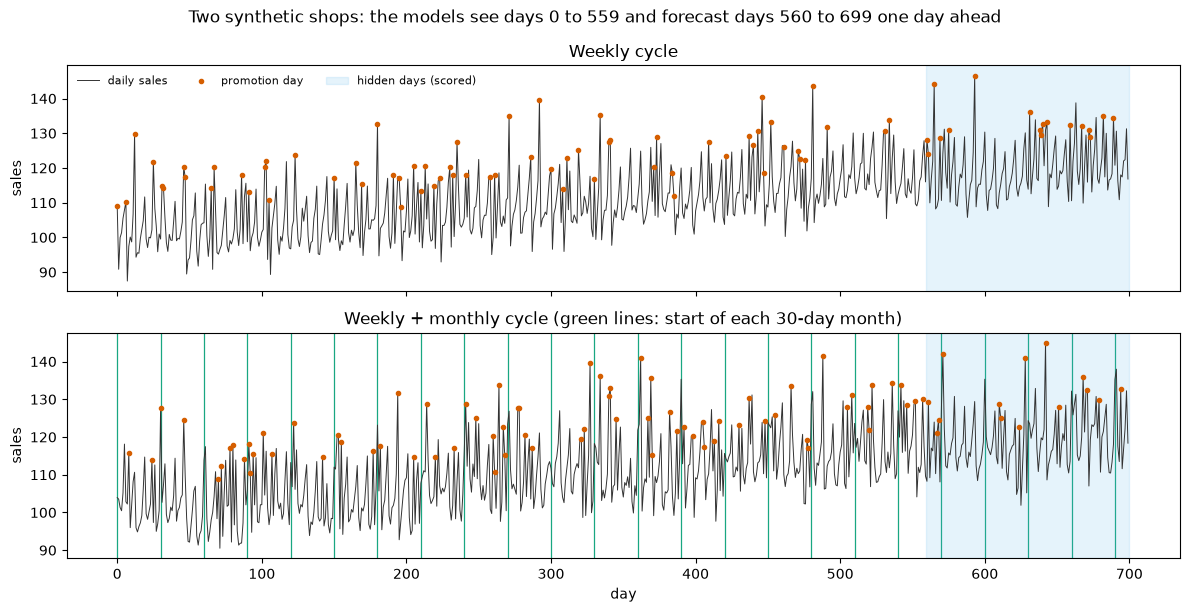

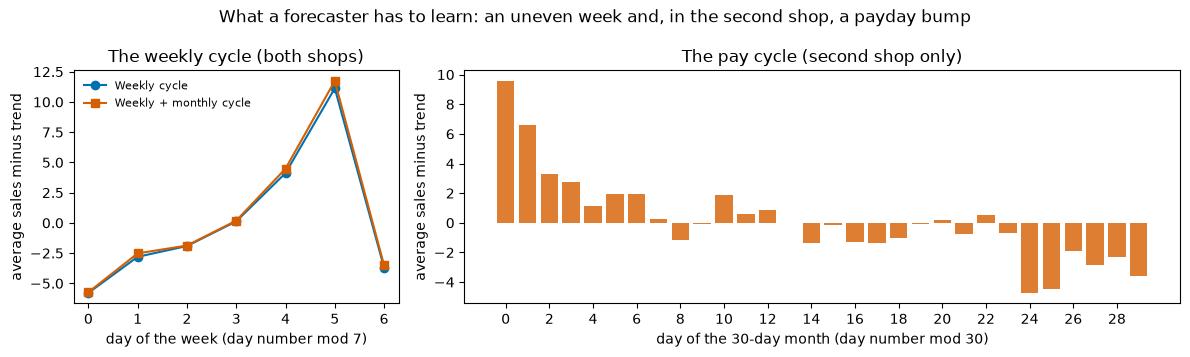

The first two hidden weeks of the weekly task:
 day  weekday (day mod 7)  sales  promotion  noise-free part
 560                    0 128.14          1           125.80
 561                    1 123.92          1           122.83
 562                    2 109.95          0           108.86
 563                    3 116.80          0           116.89
 564                    4 121.99          0           120.92
 565                    5 144.22          1           142.95
 566                    6 108.20          0           106.98
 567                    0 108.94          0           111.01
 568                    1 111.05          0           114.04
 569                    2 128.55          1           130.07
 570                    3 110.64          0           111.10
 571                    4 124.16          0           121.13
 572                    5 131.17          0           128.16
 573                    6 118.69          0           113.19


In [7]:
def plot_sales():
    fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True)
    for ax, task in zip(axes, ["weekly", "two-cycles"]):
        d = lstm_task(task)
        days = np.arange(N_DAYS)
        ax.plot(days, d["y"], color="#333333", lw=0.7, label="daily sales")
        ax.scatter(days[d["promo"] == 1], d["y"][d["promo"] == 1], s=9, color="#d55e00", zorder=3, label="promotion day")
        ax.axvspan(N_VIS - 0.5, N_DAYS, color="#56b4e9", alpha=0.15, label="hidden days (scored)")
        if LSTM_TASKS[task]["monthly"]:
            for start in range(0, N_DAYS, 30):
                ax.axvline(start, color="#009e73", lw=0.9, alpha=0.9, zorder=0)
        ax.set(ylabel="sales", title={"weekly": "Weekly cycle", "two-cycles": "Weekly + monthly cycle (green lines: start of each 30-day month)"}[task])
    axes[0].legend(loc="upper left", ncol=3, fontsize=8, frameon=False)
    axes[1].set_xlabel("day")
    fig.suptitle("Two synthetic shops: the models see days 0 to 559 and forecast days 560 to 699 one day ahead", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIGURES / "sales_series.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_sales()


def plot_cycles():
    """Average visible sales by weekday and by day of the 30-day month, after removing the trend and leaving out
    promotion days and the days after them."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
    for task, colour, marker in [("weekly", "#0072B2", "o"), ("two-cycles", "#D55E00", "s")]:
        d = lstm_task(task)
        days = np.arange(N_VIS)
        plain = (d["promo"][:N_VIS] == 0) & (np.r_[0, d["promo"][:N_VIS - 1]] == 0)
        detrended = d["y"][:N_VIS] - 100 - 0.03 * days
        by_weekday = [detrended[plain & (days % 7 == k)].mean() for k in range(7)]
        label = {"weekly": "Weekly cycle", "two-cycles": "Weekly + monthly cycle"}[task]
        axes[0].plot(range(7), by_weekday, color=colour, marker=marker, label=label)
        if task == "two-cycles":
            by_month_day = [detrended[plain & (days % 30 == k)].mean() for k in range(30)]
            axes[1].bar(range(30), by_month_day, color=colour, alpha=0.8)
    axes[0].set(xlabel="day of the week (day number mod 7)", ylabel="average sales minus trend",
                title="The weekly cycle (both shops)", xticks=range(7))
    axes[0].legend(fontsize=8, frameon=False)
    axes[1].set(xlabel="day of the 30-day month (day number mod 30)", ylabel="average sales minus trend",
                title="The pay cycle (second shop only)", xticks=range(0, 30, 2))
    fig.suptitle("What a forecaster has to learn: an uneven week and, in the second shop, a payday bump", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIGURES / "sales_cycles.png", dpi=150, bbox_inches="tight")
    plt.show()


plot_cycles()
dw = lstm_task("weekly")
week = pd.DataFrame({"day": np.arange(560, 574), "weekday (day mod 7)": np.arange(560, 574) % 7,
                     "sales": dw["y"][560:574], "promotion": dw["promo"][560:574],
                     "noise-free part": dw["det"][560:574].round(2)})
print("The first two hidden weeks of the weekly task:")
print(week.to_string(index=False))

### The LSTM tasks

Each task is a 700-day sales series. Sales start near 100 and grow by 0.03 a day. On top of that sit a weekly cycle
(-6, -3, -2, 0, +4, +11 and -4 on the seven days of the week), promotions on about 12% of days (+15 on the day and -6
on the day after), and noise that carries over from day to day: each day's noise is 0.6 times the previous day's plus
a fresh random amount with a standard deviation of 2. The second task adds a 30-day pay cycle: sales are higher on the
first four days of each 30-day month (+9.9, +5.9, +2.9, +0.9) and 3.1 lower in its last six days.

The models see days 0 to 559. They are scored on days 560 to 699, 140 forecasts of one day ahead. For each hidden day
the tester feeds the true values of the previous 28 days (35 for the two-cycle task, so that a full month fits in the
window) together with the promotion flags, including the flag of the day being forecast. In the second chart the
weekly profile is the same in both shops, and the pay cycle shows as a tall first bar and a dip at days 24 to 29. The
table lists the first two hidden weeks: day 565 is a promotion (144.22), and the day after it drops to 108.20.

## 3. The request and the models

Every model gets the same prompt for a task, once per request, with no conversation history. The prompt says there are
no tools and that the tester will not train, repair or choose anything; it states the task, the size limits, the exact
inference code that will run the answer, the required JSON format, and then the labelled rows or the sales history.
The forest prompt for 600 rows is 25,421 characters, the 1,500-row prompt 60,522, and each LSTM prompt 9,369. The
output below shows the forest prompt up to the first rows and the LSTM prompt up to the start of the history.

In [8]:
prompt600 = task_prompt("rules-600").split("\n")
first_row = next(i for i, line in enumerate(prompt600) if line.startswith("LABELLED ROWS")) + 1
print("\n".join(prompt600[:first_row + 6]))
print(f"... {len(prompt600) - first_row - 7} more rows ...")
print(prompt600[-1])
print("\nThe LSTM prompt, up to the start of the history:")
weekly_prompt = task_prompt("weekly")
print(weekly_prompt[:weekly_prompt.index("HISTORY")] + "HISTORY (day, sales, promotion flag for that day):\n0,"
      + weekly_prompt.split("\n0,", 1)[1][:60] + " ...")

You are the sole author of a random forest classifier. You have NO tools, code execution,
calculator, files, web or other agents. Reason internally. The tester loads your JSON unchanged and only
runs the inference code below. It will not train, prune, repair or choose anything.

TASK: predict a class 0, 1, 2 or 3 from eight features. x0..x6 are numbers between 0 and 10. x7 is a
category code 0, 1, 2 or 3; the codes are names, so their order means nothing. Not every feature need
matter, and the classes need not follow axis-aligned boundaries. Labels may be noisy. The 600 labelled rows
below are the ONLY data you receive. You are scored by accuracy on 5,000 hidden rows from the same source.

MODEL LIMITS: at most 20 trees. In each tree, a path from the root to a leaf passes through at most
8 internal (split) nodes, and the tree has at most 511 nodes. Feature indices 0..7.

EXACT INFERENCE CODE (read, do not execute):
import numpy as np
def tree_predict(tree, x):
    # tree["nodes"] is a 

### The models

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| Claude Opus 5.5 | `claude-opus-5-5` (the CLI exposes no dated snapshot) | Anthropic, `claude -p` (Claude Code 2.1.296) | Not published | Effort high, no tools, output allowance 128,000 tokens per message | Wrote 91% forests in the pilot; Anthropic's main frontier model |
| Claude Fable 5.1 | `claude-fable-5-1` | Anthropic, `claude -p` | Not published | Effort high, no tools, 64,000 tokens per message (the model's cap) | Anthropic's largest model; wrote both the best and a poor pilot forest |
| Claude Sonnet 5.5 | `claude-sonnet-5-5` | Anthropic, `claude -p` | Not published | Effort high, no tools, 128,000 tokens per message | A cheaper Claude model that scored 38 to 42% on the pilot forest, to show where the ability starts |
| GPT-6.1 Sol | `gpt-6.1-sol` (no dated snapshot exposed) | OpenAI, `codex exec` 0.160.1 with shell, code, browser, skills and multi-agent features switched off | Not published | Reasoning effort high | OpenAI's strongest model available through its CLI |
| Muse Wonder Full | `muse-wonder-full-1.0` | Meta, `muse exec` 1.4.14, preset `empty` (no tools) | Not published | Reasoning effort high | Meta's strongest Muse model |
| Kimi K3.1 Pro | `moonshotai/kimi-k3.1-pro-20261023` | OpenRouter, provider Moonshot AI | 2.8 trillion parameters, 104 billion active; mxfp4 | Reasoning effort high, `max_tokens` 128,000 | Highest-ranked large open-weight model on Artificial Analysis on 9 November |
| GLM 5.3 | `z-ai/glm-5.3-20260816` | OpenRouter, provider Z.AI | 753 billion, 40 billion active; fp8 | Reasoning effort high, `max_tokens` 128,000 | Third-ranked large open-weight model |
| DeepSeek V4.1 Flash | `deepseek/deepseek-v4.1-flash-20261017` | OpenRouter, provider DeepSeek | 552 billion, 16 billion active; precision not published | Reasoning effort high, `max_tokens` 128,000 | Second-ranked large open-weight model, at a small fraction of the others' price |

None of the models could run code. The Claude, Codex and Muse command lines were set up with every tool switched off,
each started in an empty folder, and the replies were checked for tool calls: there were none in 144 requests. The
open-weight models were called through OpenRouter's chat interface without tools. Every model got reasoning effort
"high". The output allowance differs in one respect described in section 8: when a Claude reply reaches its
per-message cap, Claude Code continues it in a second message, which the open-weight models' hard 128,000-token limit
does not allow.

The next two cells define the tracing helper (each fresh call is sent to a local Langfuse instance when one is
running, for later inspection) and the four ways of calling a model, the cache and the retry rule.

In [9]:
LANGFUSE_HOST = os.environ.get("LANGFUSE_HOST", "http://localhost:3300").rstrip("/")
LANGFUSE_AUTH = (os.environ.get("LANGFUSE_PUBLIC_KEY", ""), os.environ.get("LANGFUSE_SECRET_KEY", ""))


def _langfuse_running():
    if not all(LANGFUSE_AUTH):
        return False
    try:
        return requests.get(f"{LANGFUSE_HOST}/api/public/health", timeout=2).ok
    except requests.RequestException:
        return False


LANGFUSE_ON = ALLOW_FRESH_CALLS and _langfuse_running()


def trace_call(cache_key, name, model, request, response, start, end, usage=None, cost_usd=None,
               session_id=None, metadata=None, error=None):
    """Send one fresh model call to the local Langfuse (AGENTS.md helper). Never raises."""
    if not LANGFUSE_ON:
        return

    def attr(k, v):
        return {"key": k, "value": {"stringValue": v if isinstance(v, str) else json.dumps(v, default=str)}}

    tags = {"key": "langfuse.trace.tags", "value": {"arrayValue": {"values": [{"stringValue": f"nb{NOTEBOOK[:2]}"}]}}}
    attrs = [attr("langfuse.observation.type", "generation"), attr("langfuse.observation.model.name", model),
             attr("langfuse.observation.input", request), attr("langfuse.observation.output", response),
             attr("langfuse.trace.name", f"{NOTEBOOK[:2]} {name}"), tags,
             attr("langfuse.environment", "notebook"), attr("langfuse.trace.metadata.notebook", NOTEBOOK),
             attr("langfuse.trace.metadata.cache_key", cache_key)]
    if usage:
        attrs.append(attr("langfuse.observation.usage_details", usage))
    if cost_usd is not None:
        attrs.append(attr("langfuse.observation.cost_details", {"total": cost_usd}))
    if session_id:
        attrs.append(attr("langfuse.session.id", f"{NOTEBOOK}/{session_id}"))
    if error:
        attrs += [attr("langfuse.observation.level", "ERROR"), attr("langfuse.observation.status_message", str(error))]
    for k, v in (metadata or {}).items():
        attrs.append(attr(f"langfuse.observation.metadata.{k}", v))
    span = {"traceId": hashlib.sha256(f"{NOTEBOOK}|{cache_key}".encode()).hexdigest()[:32],
            "spanId": hashlib.sha256(f"{NOTEBOOK}|{cache_key}|gen|0".encode()).hexdigest()[:16],
            "name": name, "kind": 1, "attributes": attrs,
            "startTimeUnixNano": str(int(start.timestamp() * 1e9)),
            "endTimeUnixNano": str(int(end.timestamp() * 1e9))}
    body = {"resourceSpans": [{"resource": {"attributes": [attr("service.name", "experiment-notebooks")]},
                               "scopeSpans": [{"scope": {"name": NOTEBOOK}, "spans": [span]}]}]}
    try:
        requests.post(f"{LANGFUSE_HOST}/api/public/otel/v1/traces", json=body, auth=LANGFUSE_AUTH, timeout=10)
    except requests.RequestException:
        pass

In [10]:
SYSTEM = "You are a numerical model author. Return only the requested JSON data."
WORK = Path(os.environ.get("NB45_WORK", str(Path.home() / ".nb45-work")))   # empty folders the CLIs start in
CODEX_EXE = Path(os.environ.get("APPDATA", "")) / "npm/node_modules/@openai/codex/node_modules/@openai/codex-win32-x64/vendor/x86_64-pc-windows-msvc/bin/codex.exe"
CODEX_INSTRUCTIONS = DATA / "codex_instructions.txt"
CODEX_FEATURES_OFF = ["apps", "plugins", "remote_plugin", "hooks", "shell_tool", "unified_exec", "view_image",
                      "image_generation", "multi_agent", "multi_agent_v2", "browser_use", "in_app_browser",
                      "computer_use", "code_mode", "code_mode_host", "skill_search", "memories", "goals",
                      "tool_suggest", "sleep_tool", "unified_exec_tty", "shell_snapshot", "browser_use_external",
                      "browser_use_full_cdp_access", "skill_mcp_dependency_install", "worktrees",
                      "workspace_dependencies", "agent_message_board", "daemon_auto_start"]


def short_path_env(drop_prefixes=()):
    """Copy of the environment with a de-duplicated PATH (cmd.exe fails on this machine's very long PATH)."""
    env = {k: v for k, v in os.environ.items() if not k.startswith(drop_prefixes)}
    seen = []
    for p in env.get("PATH", env.get("Path", "")).split(os.pathsep):
        if p and p not in seen and os.path.isdir(p):
            seen.append(p)
    env.pop("Path", None)
    env["PATH"] = os.pathsep.join(seen)
    return env


def build_request(model_key, task, repeat):
    info = MODEL_INFO[model_key]
    prompt = task_prompt(task)
    req = {"model": info["model"], "vendor": info["vendor"], "effort": EFFORT, "task": task, "repeat": repeat,
           "prompt": prompt}
    if info["vendor"] == "claude":
        req.update(system=SYSTEM, max_output_tokens=MAX_OUTPUT_TOKENS, budget_usd=20, tools=[])
    elif info["vendor"] == "codex":
        req.update(instructions=CODEX_INSTRUCTIONS.read_text(encoding="utf-8"), tools=[],
                   features_off=CODEX_FEATURES_OFF)
    elif info["vendor"] == "muse":
        req.update(preset="empty", tools=[])
    else:
        req.update(permaslug=info["permaslug"], provider=info["provider"], max_tokens=MAX_OUTPUT_TOKENS,
                   messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}])
        req.pop("prompt")
    return req


def cache_key(req):
    return hashlib.sha256(json.dumps(req, sort_keys=True).encode()).hexdigest()


def cache_path(model_key, task, repeat):
    return RESPONSES / task / model_key / f"r{repeat}.json"


def _now():
    return dt.datetime.now(dt.timezone.utc)


def _run_cli(cmd, prompt, cwd, env, stdin_text=True):
    """Run a CLI with a hard timeout; returns (stdout, stderr, exit code or 'timeout')."""
    proc = subprocess.Popen(cmd, cwd=cwd, env=env, stdin=subprocess.PIPE if stdin_text else subprocess.DEVNULL,
                            stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, encoding="utf-8",
                            errors="replace")
    try:
        out, err = proc.communicate(prompt if stdin_text else None, timeout=CALL_TIMEOUT_S)
        return out, err, proc.returncode
    except subprocess.TimeoutExpired:
        proc.kill()
        out, err = proc.communicate()
        return out, err, "timeout"


def call_claude(req, workdir):
    (workdir / "mcp.json").write_text('{"mcpServers":{}}', encoding="utf-8")
    cmd = [shutil.which("claude"), "--print", "--model", req["model"], "--effort", req["effort"], "--tools", "",
           "--safe-mode", "--disable-slash-commands", "--strict-mcp-config", "--mcp-config", str(workdir / "mcp.json"),
           "--disallowedTools", "mcp__*", "--system-prompt", req["system"], "--output-format", "stream-json",
           "--verbose", "--max-budget-usd", str(req["budget_usd"])]
    env = short_path_env(("CLAUDE_", "CODEX_", "ANTHROPIC_API_KEY"))
    env["CLAUDE_CODE_MAX_OUTPUT_TOKENS"] = str(req["max_output_tokens"])
    out, err, code = _run_cli(cmd, req["prompt"], workdir, env)
    events = [json.loads(l) for l in out.splitlines() if l.strip().startswith("{")]
    result = next((e for e in reversed(events) if e.get("type") == "result"), {})
    blocks = [b for e in events if e.get("type") == "assistant" for b in e["message"].get("content", [])]
    tools = [b for b in blocks if b.get("type") == "tool_use"]
    usage = result.get("usage") or {}
    thinking = (usage.get("output_tokens_details") or {}).get("thinking_tokens")
    status = "timeout" if code == "timeout" else ("ok" if result.get("subtype") == "success" else "error")
    if status == "ok" and result.get("stop_reason") == "max_tokens":
        status = "truncated"
    return dict(answer=result.get("result", "") or "", status=status, exit_code=code,
                stop_reason=result.get("stop_reason"), subtype=result.get("subtype"),
                usage=dict(input_total=sum(usage.get(k) or 0 for k in ("input_tokens", "cache_creation_input_tokens",
                                                                        "cache_read_input_tokens")) if usage else None,
                           cache_read=usage.get("cache_read_input_tokens"), output_total=usage.get("output_tokens"),
                           reasoning=thinking),
                cost_usd=result.get("total_cost_usd"), cost_basis="Claude Code list-price equivalent",
                tool_events=len(tools), reasoning_text=None, stderr=err[-3000:],
                raw=dict(result={k: v for k, v in result.items() if k != "result"},
                         text_blocks=[b.get("text", "") for b in blocks if b.get("type") == "text"]))


_codex_preflight_done = threading.Lock(), []


def codex_command(req, workdir):
    flags = ['model_reasoning_effort="%s"' % req["effort"], 'approval_policy="never"', 'sandbox_mode="read-only"',
             'web_search="disabled"', "project_doc_max_bytes=0",
             "model_instructions_file=" + json.dumps(str(CODEX_INSTRUCTIONS.resolve())), "mcp_servers={}",
             "skills.bundled.enabled=false", "skills.include_instructions=false",
             "features.skip_host_skill_discovery=true"] + [f"features.{f}=false" for f in req["features_off"]]
    config = [x for f in flags for x in ("-c", f)]
    return [str(CODEX_EXE), "exec", "--ignore-user-config", "--ignore-rules", "--ephemeral", "--skip-git-repo-check",
            "--json", "--color", "never", "-C", str(workdir), "-m", req["model"]] + config + ["-"], config


def call_codex(req, workdir):
    cmd, config = codex_command(req, workdir)
    env = short_path_env(("CODEX_THREAD_ID", "CODEX_INTERNAL_ORIGINATOR_OVERRIDE"))
    lock, done = _codex_preflight_done
    with lock:
        if not done:   # confirm once that no skills, AGENTS.md or tool instructions reach the model
            pre = subprocess.run([str(CODEX_EXE), "-C", str(workdir)] + config + ["debug", "prompt-input", "PREFLIGHT"],
                                 env=env, capture_output=True, text=True, encoding="utf-8", timeout=120)
            assert pre.returncode == 0, pre.stderr[-2000:]
            assert not any(s in pre.stdout for s in ("<skills_instructions>", "### Available skills",
                                                      "# AGENTS.md instructions")), "Codex prompt has extra context"
            (DATA / "codex_preflight.txt").write_text(pre.stdout, encoding="utf-8")
            done.append(True)
    out, err, code = _run_cli(cmd, req["prompt"], workdir, env)
    events = [json.loads(l) for l in out.splitlines() if l.strip().startswith("{")]
    items = [e["item"] for e in events if e.get("type") == "item.completed" and "item" in e]
    answers = [i.get("text", "") for i in items if i.get("type") == "agent_message"]
    reasoning = [i.get("text", "") for i in items if i.get("type") == "reasoning"]
    tools = [i for i in items if i.get("type") not in ("agent_message", "reasoning", "error")]
    notices = [i.get("message", "") for i in items if i.get("type") == "error"]
    usage = next((e.get("usage") for e in events if e.get("type") == "turn.completed"), None) or {}
    failed = next((e for e in events if e.get("type") in ("turn.failed", "error")), None)
    cached = usage.get("cached_input_tokens", 0) or 0
    inp, outp = usage.get("input_tokens"), usage.get("output_tokens")
    cost = None if inp is None else ((inp - cached) * 2.0 + cached * 0.10 + (outp or 0) * 10.0) / 1e6
    status = "timeout" if code == "timeout" else ("ok" if answers and not failed else "error")
    return dict(answer=answers[-1] if answers else "", status=status, exit_code=code, stop_reason=None,
                usage=dict(input_total=inp, cache_read=cached, output_total=outp,
                           reasoning=usage.get("reasoning_output_tokens")),
                cost_usd=cost, cost_basis="API equivalent at US$2 / 0.10 / 10 per million input / cached / output",
                tool_events=len(tools), reasoning_text="\n\n".join(reasoning) or None, stderr=err[-3000:],
                raw=dict(failed=failed, n_events=len(events), item_types=sorted({i.get("type") for i in items}),
                         notices=notices, usage=usage))


def call_muse(req, workdir):
    prompt_file = workdir / "prompt.txt"
    prompt_file.write_text(req["prompt"], encoding="utf-8")
    cmd = [shutil.which("muse"), "exec", "--json", "--preset", req["preset"], "--model", req["model"],
           "--reasoning-effort", req["effort"], "--prompt-file", str(prompt_file)]
    out, err, code = _run_cli(cmd, None, workdir, short_path_env(), stdin_text=False)
    events = [json.loads(l) for l in out.splitlines() if l.strip().startswith("{")]
    by_type = {}
    for e in events:
        by_type.setdefault(e.get("payload_type"), []).append(e.get("payload") or {})
    terminal = (by_type.get("run.terminal.completed") or by_type.get("run.terminal.failed") or [{}])[-1]
    usage = ((by_type.get("run.usage") or [{}])[-1].get("models") or [{}])[0]
    tools = [t for t in by_type if t and "tool" in t]
    status = "timeout" if code == "timeout" else ("ok" if terminal.get("terminal") == "completed" else "error")
    return dict(answer=terminal.get("text") or "", status=status, exit_code=code, stop_reason=terminal.get("reason"),
                usage=dict(input_total=usage.get("input_tokens"), cache_read=usage.get("cached_tokens"),
                           output_total=usage.get("output_tokens"), reasoning=usage.get("reasoning_tokens")),
                cost_usd=None, cost_basis="subscription; no per-call price published",
                tool_events=sum(len(by_type[t]) for t in tools), reasoning_text=None, stderr=err[-3000:],
                raw=dict(payload_types=sorted(t for t in by_type if t), terminal=terminal,
                         usage=(by_type.get("run.usage") or [{}])[-1]))


def call_openrouter(req, workdir):
    body = {"model": req["model"], "messages": req["messages"], "max_tokens": req["max_tokens"],
            "reasoning": {"effort": req["effort"]}, "stream": True, "usage": {"include": True},
            "provider": {"order": [req["provider"]], "allow_fallbacks": False, "require_parameters": True}}
    headers = {"Authorization": "Bearer " + os.environ["OPENROUTER_API_KEY"], "X-Title": "experiment-notebooks nb45"}
    content, reasoning, usage, finish, provider, err = [], [], {}, None, None, None
    deadline = time.monotonic() + CALL_TIMEOUT_S
    try:
        with requests.post("https://openrouter.ai/api/v1/chat/completions", json=body, headers=headers,
                           stream=True, timeout=(30, 600)) as r:
            if r.status_code != 200:
                return dict(answer="", status="error", exit_code=r.status_code, stop_reason=None, usage={},
                            cost_usd=None, cost_basis="OpenRouter charge", tool_events=0, reasoning_text=None,
                            stderr=r.text[-3000:], raw=dict(http_status=r.status_code))
            for line in r.iter_lines(decode_unicode=True):
                if time.monotonic() > deadline:
                    err = "timeout"
                    break
                if not line or not line.startswith("data: ") or line == "data: [DONE]":
                    continue
                chunk = json.loads(line[6:])
                if chunk.get("error"):
                    err = chunk["error"]
                    continue
                provider = chunk.get("provider", provider)
                usage = chunk.get("usage") or usage
                for ch in chunk.get("choices", []):
                    delta = ch.get("delta") or {}
                    content.append(delta.get("content") or "")
                    reasoning.append(delta.get("reasoning") or "")
                    finish = ch.get("finish_reason") or finish
    except (requests.RequestException, json.JSONDecodeError) as exc:
        err = f"{type(exc).__name__}: {exc}"
    details = usage.get("completion_tokens_details") or {}
    prompt_details = usage.get("prompt_tokens_details") or {}
    status = "timeout" if err == "timeout" else ("error" if err else ("truncated" if finish == "length" else "ok"))
    return dict(answer="".join(content), status=status, exit_code=None, stop_reason=finish,
                usage=dict(input_total=usage.get("prompt_tokens"), cache_read=prompt_details.get("cached_tokens"),
                           output_total=usage.get("completion_tokens"), reasoning=details.get("reasoning_tokens")),
                cost_usd=usage.get("cost"), cost_basis="OpenRouter charge", tool_events=0,
                reasoning_text="".join(reasoning) or None, stderr=str(err)[-3000:] if err else "",
                raw=dict(provider=provider, finish_reason=finish, usage=usage))


CALLERS = {"claude": call_claude, "codex": call_codex, "muse": call_muse, "openrouter": call_openrouter}
_locks = {}
_locks_guard = threading.Lock()
MAX_ATTEMPTS = 3


def get_answer(model_key, task, repeat):
    """Return the cached record for one request, calling the model only when fresh calls are allowed.
    A transport error (CLI crash, HTTP error) is retried up to three times; every attempt is logged."""
    req = build_request(model_key, task, repeat)
    key = cache_key(req)
    path = cache_path(model_key, task, repeat)
    with _locks_guard:
        lock = _locks.setdefault(key, threading.Lock())
    with lock:
        if path.exists():
            rec = json.loads(path.read_text(encoding="utf-8"))
            assert rec["cache_key"] == key, f"stale cache row {path}"
            return rec
        if not ALLOW_FRESH_CALLS:
            raise RuntimeError(f"no cached answer for {model_key}/{task}/r{repeat}; set NB45_FRESH=1 to call")
        info = MODEL_INFO[model_key]
        for attempt in range(1, MAX_ATTEMPTS + 1):
            workdir = WORK / f"{task}-{model_key}-r{repeat}"
            shutil.rmtree(workdir, ignore_errors=True)
            workdir.mkdir(parents=True)
            start, tick = _now(), time.monotonic()
            try:
                out = CALLERS[info["vendor"]](req, workdir)
            except Exception as exc:                       # a harness or transport failure, not a model answer
                out = dict(answer="", status="error", stderr=f"{type(exc).__name__}: {exc}", usage={}, cost_usd=None,
                           tool_events=0, raw={})
            end = _now()
            rec = dict(cache_key=key, model_key=model_key, task=task, repeat=repeat, attempt=attempt, request=req,
                       started_utc=start.isoformat(), finished_utc=end.isoformat(),
                       wall_seconds=round(time.monotonic() - tick, 1), **out)
            with open(DATA / "attempts.jsonl", "a", encoding="utf-8") as log:
                log.write(json.dumps({k: rec.get(k) for k in ("model_key", "task", "repeat", "attempt", "status",
                                      "started_utc", "wall_seconds", "cost_usd", "stderr")}) + "\n")
            u = rec["usage"] or {}
            usage = None
            if u.get("input_total") is not None:
                cached, think, out_total = u.get("cache_read") or 0, u.get("reasoning") or 0, u.get("output_total") or 0
                usage = {"input": u["input_total"] - cached, "input_cache_read": cached,
                         "output": out_total - think if out_total >= think else out_total, "output_reasoning": think}
            trace_call(key, f"{task} {model_key}", info.get("permaslug", info["model"]), req, rec["answer"], start,
                       end, usage=usage, cost_usd=rec.get("cost_usd"), session_id=f"{task}/{model_key}",
                       metadata=dict(task=task, repeat=repeat, attempt=attempt, status=rec["status"]),
                       error=rec["stderr"] if rec["status"] == "error" else None)
            if rec["status"] != "error" or attempt == MAX_ATTEMPTS:
                break
            time.sleep(30 * attempt)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(rec, indent=1), encoding="utf-8")
        return rec

The cell below asks for all 144 replies. With fresh calls switched off it only reads them from `data/responses/`.
During the collection on 9 November it ran with up to eight Claude, three Codex, three Muse and ten OpenRouter
requests in flight at once; the slowest single request (Muse Wonder Full on the 600-row task) took 51 minutes.

In [11]:
from concurrent.futures import ThreadPoolExecutor

CONCURRENCY = {"claude": 5, "codex": 2, "muse": 2, "openrouter": 6}   # parallel requests per interface
jobs = [(m, t, r) for r in range(N_REPEATS) for t in TASKS for m in MODELS]
pools = {vendor: ThreadPoolExecutor(n) for vendor, n in CONCURRENCY.items()}
futures = {job: pools[MODEL_INFO[job[0]]["vendor"]].submit(get_answer, *job) for job in jobs}
records = {job: f.result() for job, f in futures.items()}
for pool in pools.values():
    pool.shutdown()
print(f"{len(records)} replies loaded ({sum(r['status'] == 'ok' for r in records.values())} finished normally); "
      f"fresh calls {'allowed' if ALLOW_FRESH_CALLS else 'off, replayed from data/responses'}")

144 replies loaded (128 finished normally); fresh calls off, replayed from data/responses


## 4. Scoring and references

A reply is first loaded by a parser that checks it against the rules the prompt states. The only text cleaning it
does is to remove one surrounding Markdown code fence. A forest must have 1 to 20 trees; every tree needs a node with
id 0, unique ids, and every child id present; no path may pass more than 8 questions or loop back on itself; every leaf
must hold four non-negative numbers. An LSTM must have exactly the six weight arrays in the stated shapes, all finite.

A reply that fails is unreadable, in one of five kinds: no reply (empty, a timeout or a transport error that persisted
after retries), cut off (the reply reached the output limit), not JSON, wrong shape, or breaks limits. A lenient
parser, which takes the first complete JSON object anywhere in the reply, is reported beside it. Unreadable replies
are counted apart from wrong answers throughout.

Readable forests are scored by accuracy on the 5,000 hidden rows: the share of rows where the predicted class equals
the label. Because 7.4% of the hidden labels are noise, the most a forest can expect is 92.6%. A second measure,
agreement with the rule, compares the predictions with the noise-free labels instead; a forest that implements the
rule exactly scores 100% on it.

LSTMs are scored by root mean squared error (RMSE) on the 140 hidden days, in units of sales: square each forecast
error, average the squares, take the square root. A forecast that is off by 1 on each of four days has RMSE 1. One
that is exact on three days and off by 4 on the fourth has the same average miss of 1 a day but RMSE 2, because RMSE
weighs large misses more. Lower is better, and the noise that no forecaster can predict puts a floor near 2.

In [12]:
class FormatFailure(Exception):
    """A reply the tester cannot load. kind is one of: no reply, cut off, not JSON, wrong shape, breaks limits."""
    def __init__(self, kind, detail=""):
        super().__init__(f"{kind}: {detail}")
        self.kind, self.detail = kind, detail


def strip_fence(text):
    """Remove one surrounding Markdown code fence, the only cleaning the strict parser does."""
    t = (text or "").strip()
    if t.startswith("```"):
        t = t.split("\n", 1)[1] if "\n" in t else ""
        if t.rstrip().endswith("```"):
            t = t.rstrip()[:-3]
    return t.strip()


def extract_json(text, lenient):
    t = strip_fence(text)
    if not t:
        raise FormatFailure("no reply", "empty answer")
    try:
        return json.loads(t)
    except json.JSONDecodeError as exc:
        if not lenient:
            raise FormatFailure("not JSON", str(exc)[:120])
    start = t.find("{")                      # lenient parser: the first complete JSON object anywhere in the reply
    while start != -1:
        try:
            return json.JSONDecoder().raw_decode(t[start:])[0]
        except json.JSONDecodeError:
            start = t.find("{", start + 1)
    raise FormatFailure("not JSON", "no complete JSON object")


def load_forest(text, lenient=False):
    """Check the forest against the rules the prompt states. A node may be the child of more than one parent (the
    prompt does not forbid it and the inference code runs it), but no path may loop or pass more than 8 questions."""
    forest = extract_json(text, lenient)
    if not isinstance(forest, dict) or set(forest) != {"trees"} or not isinstance(forest["trees"], list):
        raise FormatFailure("wrong shape", "top level must be {\"trees\": [...]}")
    if not 1 <= len(forest["trees"]) <= MAX_TREES:
        raise FormatFailure("breaks limits", f"{len(forest['trees'])} trees")
    for t in forest["trees"]:
        try:
            nodes = {n["id"]: n for n in t["nodes"]}
        except (TypeError, KeyError):
            raise FormatFailure("wrong shape", "tree without a nodes list of objects with ids")
        if 0 not in nodes or len(nodes) != len(t["nodes"]):
            raise FormatFailure("wrong shape", "missing root or repeated node id")
        if len(nodes) > MAX_NODES:
            raise FormatFailure("breaks limits", f"{len(nodes)} nodes in one tree")
        stack = [(0, 0, ())]
        while stack:
            i, splits, path = stack.pop()
            if i not in nodes or i in path:
                raise FormatFailure("wrong shape", f"node {i} missing or part of a loop")
            n = nodes[i]
            if "leaf" in n:
                leaf = n["leaf"]
                if not (isinstance(leaf, list) and len(leaf) == N_CLASS and all(isinstance(v, (int, float)) for v in leaf)
                        and np.all(np.isfinite(leaf)) and min(leaf) >= 0):
                    raise FormatFailure("wrong shape", f"leaf {i} is not 4 non-negative numbers")
            else:
                if splits >= MAX_SPLITS:
                    raise FormatFailure("breaks limits", f"a path passes more than {MAX_SPLITS} splits")
                if not (isinstance(n.get("feature"), int) and 0 <= n["feature"] < N_FEAT
                        and isinstance(n.get("threshold"), (int, float)) and np.isfinite(n["threshold"])):
                    raise FormatFailure("wrong shape", f"split {i} has a bad feature or threshold")
                stack += [(n.get("left"), splits + 1, path + (i,)), (n.get("right"), splits + 1, path + (i,))]
    return forest


def shares_nodes(forest):
    """True when some node has two parents, so the 'tree' is strictly a graph. The pilot's loader rejected this."""
    for t in forest["trees"]:
        children = [c for n in t["nodes"] if "leaf" not in n for c in (n["left"], n["right"])]
        if len(children) != len(set(children)):
            return True
    return False


def load_lstm(text, lenient=False):
    d = extract_json(text, lenient)
    if not isinstance(d, dict) or set(d) != set(SHAPES):
        raise FormatFailure("wrong shape", f"keys {sorted(d) if isinstance(d, dict) else type(d).__name__}")
    arrays = {}
    for k, s in SHAPES.items():
        try:
            a = np.asarray(d[k], dtype=float)
        except (TypeError, ValueError):
            raise FormatFailure("wrong shape", f"{k} is not a numeric array")
        if a.shape != s or not np.isfinite(a).all():
            raise FormatFailure("wrong shape", f"{k} has shape {a.shape}, expected {s}")
        arrays[k] = a
    return arrays


def reply_text(rec):
    """The model's reply. When a Claude reply reaches the per-message output cap (64,000 tokens for Fable 5.1),
    Claude Code continues it in a second message and reports only the last one as the result, so the text of all
    the reply's messages is joined here."""
    blocks = (rec.get("raw") or {}).get("text_blocks") or []
    if rec["request"]["vendor"] == "claude" and len(blocks) > 1:
        return "".join(blocks)
    return rec.get("answer") or ""


def load_answer(rec, lenient=False):
    """Load one cached reply. Transport errors, timeouts and cut-off replies are format failures too."""
    if rec["status"] in ("error", "timeout") and not rec.get("answer"):
        raise FormatFailure("no reply", rec["status"])
    if rec["status"] == "truncated":
        raise FormatFailure("cut off", "the reply hit the output limit")
    loader = load_lstm if rec["task"] in LSTM_TASKS else load_forest
    return loader(reply_text(rec), lenient)

In [13]:
def forest_predict_all(forest, X):
    """Vectorised version of RF_CODE; checked against the exact inference code below."""
    votes = np.zeros((len(X), N_CLASS))
    for t in forest["trees"]:
        nodes = {n["id"]: n for n in t["nodes"]}
        idx = np.zeros(len(X), dtype=object)
        out = np.zeros((len(X), N_CLASS))
        stack = [(0, np.arange(len(X)))]
        while stack:
            i, rows = stack.pop()
            n = nodes[i]
            if "leaf" in n:
                out[rows] = n["leaf"]
            else:
                go_left = X[rows, n["feature"]] <= n["threshold"]
                stack += [(n["left"], rows[go_left]), (n["right"], rows[~go_left])]
        votes += out
    return np.argmax(votes / len(forest["trees"]), axis=1)


def forest_predict_exact(forest, X):
    env = {}
    exec(RF_CODE, env)
    return np.array([env["forest_predict"](forest, x) for x in X])


def forest_structure(forest):
    splits = [n for t in forest["trees"] for n in t["nodes"] if "leaf" not in n]
    per_feature = np.bincount([n["feature"] for n in splits], minlength=N_FEAT)

    def depth(nodes, i=0):
        n = nodes[i]
        return 0 if "leaf" in n else 1 + max(depth(nodes, n["left"]), depth(nodes, n["right"]))
    return dict(trees=len(forest["trees"]), nodes=sum(len(t["nodes"]) for t in forest["trees"]),
                splits_by_feature=per_feature.tolist(),
                max_depth=max(depth({n["id"]: n for n in t["nodes"]}) for t in forest["trees"]))


def score_forest(pred_hidden, pred_visible, d):
    clean, yt = d["clean"], d["yt"]
    out = dict(accuracy=float(np.mean(pred_hidden == yt)), agreement_with_rule=float(np.mean(pred_hidden == clean)),
               visible_accuracy=float(np.mean(pred_visible == d["yv"])))
    out["by_true_class"] = {c: float(np.mean(pred_hidden[clean == c] == yt[clean == c])) for c in range(N_CLASS)}
    return out

In [14]:
def lstm_windows(y, promo, window, start, end):
    """Input tensors [n, window, 2] for forecasting days start..end-1, exactly as the prompt describes."""
    return np.array([np.c_[(y[t - window:t] - 100) / 20, promo[t - window + 1:t + 1]] for t in range(start, end)])


def unpack(theta):
    parts, o = {}, 0
    for k, s in SHAPES.items():
        n = int(np.prod(s))
        parts[k] = theta[o:o + n].reshape(s)
        o += n
    return parts


def pack(arrays):
    return np.concatenate([np.asarray(arrays[k], dtype=float).ravel() for k in SHAPES])


def lstm_batch(p, X):
    """Vectorised version of the prompt's lstm_predict for many windows; returns normalised forecasts."""
    with np.errstate(over="ignore"):            # a saturated gate overflows exp(); the result (0 or 1) is still exact
        return _lstm_batch(p, X)


def _lstm_batch(p, X):
    sig = lambda z: 1 / (1 + np.exp(-z))
    h = np.zeros((len(X), H))
    c = np.zeros((len(X), H))
    for k in range(X.shape[1]):
        a = X[:, k] @ p["W_ih"].T + h @ p["W_hh"].T + p["b_ih"] + p["b_hh"]
        i, f, g, o = sig(a[:, :H]), sig(a[:, H:2 * H]), np.tanh(a[:, 2 * H:3 * H]), sig(a[:, 3 * H:])
        c = f * c + i * g
        h = o * np.tanh(c)
    return h @ p["W_out"][0] + p["b_out"][0]


def lstm_exact(arrays, X, window):
    env = {}
    exec(lstm_code(window), env)
    return np.array([env["denormalise"](env["lstm_predict"](x, **arrays)) for x in X])


def score_forecast(pred, d):
    """RMSE on the 140 hidden days, overall and for the day types the generator treats differently."""
    y, promo = d["y"], d["promo"]
    truth = y[N_VIS:]
    err = pred - truth
    days = np.arange(N_VIS, N_DAYS)
    after = np.r_[0, promo[:-1]][N_VIS:]
    rmse = lambda m: float(np.sqrt(np.mean(err[m] ** 2))) if m.any() else None
    out = dict(rmse=rmse(np.ones_like(err, bool)), rmse_promo_day=rmse(promo[N_VIS:] == 1),
               rmse_day_after_promo=rmse(after == 1), rmse_other_days=rmse((promo[N_VIS:] == 0) & (after == 0)),
               mean_error_by_weekday=[float(err[days % 7 == k].mean()) for k in range(7)],
               rmse_by_weekday=[rmse(days % 7 == k) for k in range(7)])
    if LSTM_TASKS[d["task"]]["monthly"]:
        phase = days % 30
        out.update(rmse_payday=rmse(phase < 4), rmse_last_week=rmse(phase >= 24),
                   rmse_mid_month=rmse((phase >= 4) & (phase < 24)))
    return out


def lag_profile(p, d, start=N_VIS, end=N_DAYS):
    """What a forecaster reads: the average change in the forecast (sales units) when one input day's sales rise
    by 1 unit, for each lag 1..window, plus the change when the promotion flag of day t or of day t-1 is switched on."""
    w = d["window"]
    X = lstm_windows(d["y"], d["promo"], w, start, end)
    base = lstm_batch(p, X)
    lags = []
    for lag in range(1, w + 1):
        Xp = X.copy()
        Xp[:, w - lag, 0] += 1 / 20
        lags.append(float(np.mean(lstm_batch(p, Xp) - base) * 20))
    flags = {}
    for name, row in (("promo_today", w - 1), ("promo_yesterday", w - 2)):
        on, off = X.copy(), X.copy()
        on[:, row, 1], off[:, row, 1] = 1, 0
        flags[name] = float(np.mean(lstm_batch(p, on) - lstm_batch(p, off)) * 20)
    return dict(lags=lags, **flags)

### The references

A written model means something only next to what the usual methods get from the same visible data.

For the forest tasks:

- Commonest class: always predict the class that is most common in the visible rows. Any useful forest beats this.
- Trained tree, 8 splits: one decision tree grown by scikit-learn with at most 8 questions on any path.
- Trained forest, same limits: scikit-learn's random forest with 20 trees and at most 8 questions per path, the same
  limits the language models had. Each tree is grown on a random resample of the rows, with a random subset of the
  features considered at each split, and the forest averages them.
- Trained forest, 200 trees: the same method with ten times as many trees and no depth limit, to show what the forest
  method gets when the size limit is lifted.
- Gradient boosting: scikit-learn's histogram gradient boosting, which adds many small trees one after another, each
  correcting the errors of the ones before. It is usually the strongest trained tree model on tables like these. It
  does not fit inside the 20-tree limit; it is here to show what training can reach.
- Noise-free rule: the generating rule itself, the 92.6% ceiling.

For the LSTM tasks:

- Repeat yesterday: tomorrow's forecast is today's sales.
- Same weekday last week: tomorrow's forecast is the sales seven days earlier, a standard seasonal rule of thumb.
- Linear model, same inputs: least squares on the same 28 (or 35) days of values and promotion flags the LSTM sees.
  It suits these series, because they are built from additive parts, but it is not an LSTM.
- Trained LSTM, same size: the same 8-unit, 393-weight network trained by gradient descent with exact gradients
  (L-BFGS), from six random starting points. The last 12 visible weeks (days 476 to 559) are held out to choose the
  starting point and when to stop; the hidden days are never used. Across all 36 candidates the hidden-day RMSE ranges
  from 2.57 to 10.1 on the weekly task, so this choice matters; the held-out weeks picked one scoring 3.87.
- True formula: the generating formula with the previous day's noise carried over, which is the best forecast
  possible. Its RMSE (1.97 on the weekly task, 1.90 on the two-cycle task) is the floor.

All references use scikit-learn or NumPy defaults with a fixed random seed. They are computed in the next cell; the
two trained LSTMs take a few minutes and are cached in `data/references/`.

In [15]:
def forest_references(task):
    from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
    from sklearn.tree import DecisionTreeClassifier
    d = forest_task(task)
    refs = {"Commonest class": np.full(len(d["Xt"]), np.bincount(d["yv"]).argmax())}
    models = {"Trained tree, 8 splits": DecisionTreeClassifier(max_depth=MAX_SPLITS, random_state=0),
              "Trained forest, same limits": RandomForestClassifier(MAX_TREES, max_depth=MAX_SPLITS, random_state=0),
              "Trained forest, 200 trees": RandomForestClassifier(200, random_state=0),
              "Gradient boosting": HistGradientBoostingClassifier(random_state=0)}
    visible = {"Commonest class": np.full(len(d["Xv"]), np.bincount(d["yv"]).argmax())}
    for name, m in models.items():
        m.fit(d["Xv"], d["yv"])
        refs[name], visible[name] = m.predict(d["Xt"]), m.predict(d["Xv"])
    refs["Noise-free rule"], visible["Noise-free rule"] = d["clean"], d["labeller"](d["Xv"])
    return {name: score_forest(refs[name], visible[name], d) for name in refs}, refs


def lstm_loss_grad(theta, X, target):
    """Mean squared error on the normalised scale and its exact gradient (backpropagation through time)."""
    p = unpack(theta)
    n, T, _ = X.shape
    b = p["b_ih"] + p["b_hh"]
    sig = lambda z: 1 / (1 + np.exp(-z))
    h, c, cache = np.zeros((n, H)), np.zeros((n, H)), []
    for k in range(T):
        a = X[:, k] @ p["W_ih"].T + h @ p["W_hh"].T + b
        i, f, g, o = sig(a[:, :H]), sig(a[:, H:2 * H]), np.tanh(a[:, 2 * H:3 * H]), sig(a[:, 3 * H:])
        c_new = f * c + i * g
        tc = np.tanh(c_new)
        cache.append((X[:, k], h, c, i, f, g, o, tc))
        c, h = c_new, o * tc
    err = h @ p["W_out"][0] + p["b_out"][0] - target
    d = 2 * err / n
    gr = {k: np.zeros_like(v) for k, v in p.items()}
    gr["W_out"][0], gr["b_out"][0] = d @ h, d.sum()
    dh, dc = d[:, None] * p["W_out"][0], np.zeros((n, H))
    for x, h_prev, c_prev, i, f, g, o, tc in reversed(cache):
        do = dh * tc
        dc = dc + dh * o * (1 - tc ** 2)
        da = np.concatenate([dc * g * i * (1 - i), dc * c_prev * f * (1 - f), dc * i * (1 - g ** 2), do * o * (1 - o)], 1)
        gr["W_ih"] += da.T @ x
        gr["W_hh"] += da.T @ h_prev
        gr["b_ih"] += da.sum(0)
        dh, dc = da @ p["W_hh"], dc * f
    gr["b_hh"] = gr["b_ih"].copy()
    return float(np.mean(err ** 2)), np.concatenate([gr[k].ravel() for k in SHAPES])


VALIDATION_START = 476   # the last 12 visible weeks (days 476..559) choose the trained LSTM's seed and length


def train_lstm(task):
    """The same LSTM trained the usual way: L-BFGS with exact gradients on visible days before day 476, six random
    starts, stopped after 50..1600 iterations; the candidate with the lowest error on days 476..559 is kept.
    The hidden days are never used. Results are cached in data/references because training takes a few minutes."""
    path = DATA / "references" / f"trained_lstm_{task}.json"
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    from scipy.optimize import minimize
    d = lstm_task(task)
    w, y, promo = d["window"], d["y"], d["promo"]
    Xa, ta = lstm_windows(y, promo, w, w, VALIDATION_START), (y[w:VALIDATION_START] - 100) / 20
    Xb, tb = lstm_windows(y, promo, w, VALIDATION_START, N_VIS), y[VALIDATION_START:N_VIS]
    candidates = []
    for seed in range(6):
        theta = np.random.default_rng(seed).normal(0, 0.2, N_LSTM)
        fb = 4 * H * IN + 4 * H * H + H                        # forget-gate part of b_ih starts at 1
        theta[fb:fb + H] = 1.0
        done = 0
        for stop in [50, 100, 200, 400, 800, 1600]:
            fit = minimize(lstm_loss_grad, theta, args=(Xa, ta), jac=True, method="L-BFGS-B",
                           options={"maxiter": stop - done})
            theta, done = fit.x, stop
            val = float(np.sqrt(np.mean((20 * lstm_batch(unpack(theta), Xb) + 100 - tb) ** 2)))
            candidates.append(dict(seed=seed, iterations=stop, validation_rmse=val, theta=theta.tolist()))
    best = min(candidates, key=lambda c: c["validation_rmse"])
    out = dict(chosen=best, candidates=candidates)
    path.parent.mkdir(exist_ok=True)
    path.write_text(json.dumps(out), encoding="utf-8")
    return out


def lstm_references(task):
    d = lstm_task(task)
    w, y, promo, det = d["window"], d["y"], d["promo"], d["det"]
    preds = {"Repeat yesterday": y[N_VIS - 1:N_DAYS - 1], "Same weekday last week": y[N_VIS - 7:N_DAYS - 7]}
    Xv, tv = lstm_windows(y, promo, w, w, N_VIS), (y[w:N_VIS] - 100) / 20
    Xt = lstm_windows(y, promo, w, N_VIS, N_DAYS)
    flat = lambda X: np.c_[X.reshape(len(X), -1), np.ones(len(X))]
    coef, *_ = np.linalg.lstsq(flat(Xv), tv, rcond=None)
    preds["Linear model, same inputs"] = 20 * flat(Xt) @ coef + 100
    trained = train_lstm(task)
    p_trained = unpack(np.asarray(trained["chosen"]["theta"]))
    preds["Trained LSTM, same size"] = 20 * lstm_batch(p_trained, Xt) + 100
    preds["True formula"] = det[N_VIS:] + 0.6 * (y[N_VIS - 1:N_DAYS - 1] - det[N_VIS - 1:N_DAYS - 1])
    linear_lags = [float(coef[2 * (w - lag)]) for lag in range(1, w + 1)]   # weight per sales unit at each lag
    extra = dict(linear_lags=linear_lags, trained_profile=lag_profile(p_trained, d), trained_choice=
                 {k: v for k, v in trained["chosen"].items() if k != "theta"},
                 trained_candidate_test_rmse=[float(np.sqrt(np.mean((20 * lstm_batch(unpack(np.asarray(c["theta"])), Xt)
                                                                     + 100 - y[N_VIS:]) ** 2)))
                                              for c in trained["candidates"]])
    return {name: score_forecast(p, d) for name, p in preds.items()}, preds, extra

### A worked example: one forest, one hidden row

Here is one reply followed from the file to a prediction. Claude Fable 5.1's first forest for the 600-row rules task
has three trees and 175 nodes. The cell traces the first hidden row through each tree using the exact inference code
from the prompt, printing every question asked.

In [16]:
def trace_row(forest, x):
    """Follow one row through every tree with the exact inference code, recording each question asked."""
    env = {}
    exec(RF_CODE, env)
    paths = []
    for t in forest["trees"]:
        nodes = {n["id"]: n for n in t["nodes"]}
        n, steps = nodes[0], []
        while "leaf" not in n:
            left = x[n["feature"]] <= n["threshold"]
            steps.append(f"x{n['feature']}={x[n['feature']]:g} {'<=' if left else '>'} {n['threshold']:g}")
            n = nodes[n["left"]] if left else nodes[n["right"]]
        paths.append((steps, n["leaf"]))
    return paths, env["forest_predict"](forest, x)


def show_worked_forest(task, model, repeat, row):
    rec = get_answer(model, task, repeat)
    forest = load_answer(rec)
    d = forest_task(task)
    x = d["Xt"][row]
    paths, pred = trace_row(forest, x)
    print(f"{MODEL_INFO[model]['label']}, {task}, request {repeat}: {len(forest['trees'])} trees, "
          f"{sum(len(t['nodes']) for t in forest['trees'])} nodes. Reply starts: {rec['answer'][:160]}...")
    print(f"\nHidden row {row}: " + ", ".join(f"x{i}={v:g}" for i, v in enumerate(x)))
    for k, (steps, leaf) in enumerate(paths):
        print(f"  tree {k}: " + " -> ".join(steps) + f" -> leaf {leaf}")
    votes = np.mean([leaf for _, leaf in paths], axis=0)
    print(f"  average vote {np.round(votes, 3).tolist()} -> class {pred} ({RULE_NAMES[pred]}); "
          f"label {d['yt'][row]}, rule says {d['clean'][row]}")

In [17]:
show_worked_forest("rules-600", "fable", 0, 0)

Claude Fable 5.1, rules-600, request 0: 3 trees, 175 nodes. Reply starts: {"trees":[{"nodes":[{"id":0,"feature":0,"threshold":2.15,"left":1,"right":2},{"id":1,"leaf":[0,0,0,0]},{"id":2,"feature":0,"threshold":7.85,"left":4,"right":3},...

Hidden row 0: x0=3.66, x1=3.62, x2=6.12, x3=9.23, x4=5.99, x5=6.97, x6=0.63, x7=0
  tree 0: x0=3.66 > 2.15 -> x0=3.66 <= 7.85 -> x0=3.66 <= 5 -> x0=3.66 > 3.5 -> x0=3.66 <= 4 -> x1=3.62 > 2.44 -> x1=3.62 <= 7.56 -> leaf [0, 0, 0, 3]
  tree 1: x1=3.62 > 2.15 -> x1=3.62 <= 7.85 -> x1=3.62 <= 5 -> x1=3.62 > 3.5 -> x1=3.62 <= 4 -> x0=3.66 > 2.44 -> x0=3.66 <= 7.56 -> leaf [0, 0, 0, 3]
  tree 2: x7=0 <= 1.5 -> x3=9.23 > 5 -> x4=5.99 > 5 -> leaf [1, 0, 0, 0]
  average vote [0.333, 0.0, 0.0, 2.0] -> class 3 (circle); label 3, rule says 3


The row has x0 = 3.66 and x1 = 3.62, which lies 1.9 from the centre (5, 5), inside the circle. Tree 0 narrows x0 into
a band between 3.5 and 4 and then checks that x1 lies between 2.44 and 7.56, the height of the circle at that band:
one step of a staircase. Tree 1 does the same with x0 and x1 swapped. Both put 3 votes on the circle class. Tree 2 is a
rule tree: it checks the category code first (x7 = 0, so not the category rule), then x3 and x4 (both above 5, so not
exactly-one) and votes 1 for rest. The average vote is 2.0 for circle against 0.33 for rest, so the forest predicts
circle, which is both the label and what the rule says.

The weights carry the design. The circle trees vote 3 and the rule tree votes 1, so the circle overrides the other
rules, exactly as in the generator. Fable did not average a crowd of noisy trees as a trained forest does. It wrote the
generating rule as a program, using the forest format as its programming language. Across all 5,000 hidden rows this
forest scores 91.5% and agrees with the rule on 98.7%.

### A worked example: one forecast

The same walk-through for a forecast. Fable's first weekly LSTM forecasts day 569, a promotion day. The tester takes the
true sales of days 541 to 568, normalises them as the prompt's code says ((sales - 100) / 20), pairs each with the
promotion flag of the following day, and runs the exact inference code from a zero state.

In [18]:
def show_worked_lstm(task, model, repeat, day):
    """Build the input rows for one hidden day exactly as the tester does, run the exact inference code and compare."""
    rec = get_answer(model, task, repeat)
    arrays = load_answer(rec)
    d = lstm_task(task)
    w = d["window"]
    X = lstm_windows(d["y"], d["promo"], w, day, day + 1)
    forecast = lstm_exact(arrays, X, w)[0]
    rows = pd.DataFrame({"input row": range(1, w + 1), "day s": range(day - w, day),
                         "sales on day s": d["y"][day - w:day], "value fed in": X[0][:, 0].round(4),
                         "promotion flag of day s+1": X[0][:, 1].astype(int)})
    print(f"{MODEL_INFO[model]['label']}, {task}, request {repeat}: forecasting day {day} "
          f"(weekday {day % 7}, promotion {'yes' if d['promo'][day] else 'no'})")
    print(rows.iloc[list(range(3)) + list(range(w - 15, w))].to_string(index=False))
    print(f"   ({w - 18} earlier rows not shown)\n")
    print(f"LSTM output {forecast:.2f}; true sales {d['y'][day]:.2f}; error {forecast - d['y'][day]:+.2f}")
    print(f"Same weekday last week would say {d['y'][day - 7]:.2f}; the noise-free part of day {day} is {d['det'][day]:.2f}")

In [19]:
show_worked_lstm("weekly", "fable", 0, day=569)

Claude Fable 5.1, weekly, request 0: forecasting day 569 (weekday 2, promotion yes)
 input row  day s  sales on day s  value fed in  promotion flag of day s+1
         1    541          114.12        0.7060                          0
         2    542          115.53        0.7765                          0
         3    543          120.11        1.0055                          0
        14    554          110.71        0.5355                          0
        15    555          116.30        0.8150                          0
        16    556          117.40        0.8700                          0
        17    557          123.55        1.1775                          0
        18    558          127.85        1.3925                          0
        19    559          115.99        0.7995                          1
        20    560          128.14        1.4070                          1
        21    561          123.92        1.1960                          0
        22    56

Fable's network forecasts 131.29 against true sales of 128.55, an error of +2.74. The noise-free part of day 569 is
130.07, so most of the miss is the day's unpredictable noise. "Same weekday last week" would have said 109.95, because
it does not know that day 569 is a promotion. The last input row carries the promotion flag 1, and section 7 shows that
Fable's weights add about 16 sales units when that flag is on, close to the generator's +15.

### Scoring every reply

The next cell loads every reply with the strict parser, sorts unreadable ones by kind, scores the readable ones and
writes one row per request to `data/results.csv`. The cell after it computes the references.

In [20]:
import warnings

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, Patch
from matplotlib.ticker import NullFormatter, PercentFormatter
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

warnings.filterwarnings("ignore", message="Mean of empty slice")   # medians of models with no readable file
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#dddddd",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
        "axes.titlesize": 12,
    }
)
MODEL_ORDER = ["opus", "fable", "sonnet", "sol", "muse", "kimi", "glm", "deepseek"]
COLORS = dict(
    zip(MODEL_ORDER, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#332288", "#882255"])
)
MARKERS = dict(zip(MODEL_ORDER, ["o", "s", "^", "D", "v", "P", "X", "*"]))
TASK_NAMES = {
    "rules-200": "Rules, 200 rows",
    "rules-600": "Rules, 600 rows",
    "rules-1500": "Rules, 1,500 rows",
    "smooth-600": "Smooth, 600 rows",
    "weekly": "Weekly cycle",
    "two-cycles": "Weekly + monthly cycle",
}
FOREST_TASKS = [t for t in TASKS if t not in LSTM_TASKS]
FAILURE_KINDS = ["no reply", "cut off", "not JSON", "wrong shape", "breaks limits"]
DETAIL_COLUMNS = (
    ["accuracy", "agreement_with_rule", "visible_accuracy"]
    + [f"acc_class{i}" for i in range(4)]
    + ["trees", "nodes", "max_depth"]
    + [f"splits_x{i}" for i in range(8)]
    + [
        "rmse",
        "rmse_promo_day",
        "rmse_day_after_promo",
        "rmse_other_days",
        "rmse_payday",
        "rmse_last_week",
        "rmse_mid_month",
    ]
    + [f"mean_error_wd{i}" for i in range(7)]
    + [f"lag_{i}" for i in range(1, 36)]
    + ["promo_today", "promo_yesterday", "visible_rmse"]
)


def flatten_metrics(metrics):
    out = {
        k: v
        for k, v in metrics.items()
        if k not in ("by_true_class", "mean_error_by_weekday", "rmse_by_weekday", "splits_by_feature", "lags")
    }
    out.update({f"acc_class{k}": v for k, v in metrics.get("by_true_class", {}).items()})
    out.update({f"mean_error_wd{i}": v for i, v in enumerate(metrics.get("mean_error_by_weekday", []))})
    out.update({f"splits_x{i}": v for i, v in enumerate(metrics.get("splits_by_feature", []))})
    out.update({f"lag_{i}": v for i, v in enumerate(metrics.get("lags", []), 1)})
    return out


def score_object(obj, task, include_profile=True):
    if task not in LSTM_TASKS:
        d = forest_data[task]
        return flatten_metrics(
            {
                **score_forest(forest_predict_all(obj, d["Xt"]), forest_predict_all(obj, d["Xv"]), d),
                **forest_structure(obj),
            }
        )
    d = lstm_data[task]
    w = d["window"]
    pred = 20 * lstm_batch(obj, lstm_windows(d["y"], d["promo"], w, N_VIS, N_DAYS)) + 100
    visible = 20 * lstm_batch(obj, lstm_windows(d["y"], d["promo"], w, w, N_VIS)) + 100
    metrics = score_forecast(pred, d)
    metrics["visible_rmse"] = float(np.sqrt(np.mean((visible - d["y"][w:N_VIS]) ** 2)))
    if include_profile:
        metrics.update(lag_profile(obj, d))
    return flatten_metrics(metrics)


def save_figure(fig, name):
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    plt.show()


def chosen_best(task, models):
    picks = []
    for model in models:
        sub = results[(results.task == task) & (results.model == model) & results.readable]
        if not sub.empty:
            row = sub.sort_values("score", ascending=task in LSTM_TASKS).iloc[0]
            picks.append((task, model, int(row["repeat"])))
    return picks

In [21]:
forest_data = {t: forest_task(t) for t in FOREST_TASKS}
lstm_data = {t: lstm_task(t) for t in LSTM_TASKS}
loaded = {}
rows = []
for task in TASKS:
    for model in MODELS:
        for repeat in range(N_REPEATS):
            path = cache_path(model, task, repeat)
            if not path.exists():
                continue
            # Read the cache directly: this cannot trigger a model call even if collection is enabled.
            try:
                rec = json.loads(path.read_text(encoding="utf-8"))
            except (OSError, json.JSONDecodeError):
                continue  # a collector may still be writing this record
            usage = rec.get("usage") or {}
            row = dict(
                task=task,
                family="lstm" if task in LSTM_TASKS else "forest",
                model=model,
                label=MODEL_INFO[model]["label"],
                repeat=repeat,
                status=rec["status"],
                readable=False,
                failure="",
                failure_detail="",
                lenient_readable=False,
                lenient_failure="",
                input_tokens=usage.get("input_total"),
                output_tokens=usage.get("output_total"),
                reasoning_tokens=usage.get("reasoning"),
                wall_minutes=(rec.get("wall_seconds") / 60 if rec.get("wall_seconds") is not None else None),
                cost_usd=rec.get("cost_usd"),
                tool_events=rec.get("tool_events"),
                score=np.nan,
                score_lenient=np.nan,
                shared_nodes=False,
                messages=((rec.get("raw") or {}).get("result") or {}).get("num_turns", 1)
                if rec["request"]["vendor"] == "claude"
                else 1,
                over_allowance=(usage.get("output_total") or 0) > MAX_OUTPUT_TOKENS,
            )
            try:
                obj = load_answer(rec)
                row["readable"] = True
                loaded[(task, model, repeat)] = obj
                metrics = score_object(obj, task)
                row.update(metrics)
                row["score"] = metrics["rmse" if task in LSTM_TASKS else "accuracy"]
                row["score_lenient"] = row["score"]
                row["shared_nodes"] = task not in LSTM_TASKS and shares_nodes(obj)
            except FormatFailure as exc:
                row.update(failure=exc.kind, failure_detail=exc.detail)
            try:
                obj_lenient = load_answer(rec, lenient=True)
                row["lenient_readable"] = True
                if not row["readable"]:
                    m = score_object(obj_lenient, task, include_profile=False)
                    row["score_lenient"] = m["rmse" if task in LSTM_TASKS else "accuracy"]
            except FormatFailure as exc:
                row["lenient_failure"] = exc.kind
            if task in LSTM_TASKS:
                d = lstm_data[task]
                baseline = np.sqrt(np.mean((d["y"][N_VIS - 7 : N_DAYS - 7] - d["y"][N_VIS:]) ** 2))
            else:
                d = forest_data[task]
                baseline = np.mean(d["yt"] == np.bincount(d["yv"]).argmax())
            row["score_fallback"] = row["score"] if row["readable"] else float(baseline)
            # the pilot's tree-only rule: a forest with a node shared by two parents counts as unreadable
            row["score_tree_only"] = np.nan if row["shared_nodes"] else row["score"]
            rows.append(row)
result_columns = (
    [
        "task",
        "family",
        "model",
        "label",
        "repeat",
        "status",
        "readable",
        "failure",
        "failure_detail",
        "lenient_readable",
        "lenient_failure",
    ]
    + DETAIL_COLUMNS
    + [
        "input_tokens",
        "output_tokens",
        "reasoning_tokens",
        "wall_minutes",
        "cost_usd",
        "tool_events",
        "score",
        "score_fallback",
        "score_lenient",
        "shared_nodes",
        "score_tree_only",
        "messages",
        "over_allowance",
    ]
)
results = pd.DataFrame(rows).reindex(columns=result_columns)
results.to_csv(DATA / "results.csv", index=False, float_format="%.6f")

In [22]:
ref_rows = []
ref_preds = {}
lstm_extra = {}
reference_json = {}
for task in TASKS:
    if task in LSTM_TASKS:
        scores, preds, extra = lstm_references(task)
        lstm_extra[task] = extra
    else:
        scores, preds = forest_references(task)
    reference_json[task] = {}
    for name, metrics in scores.items():
        flat = flatten_metrics(metrics)
        ref_preds[(task, name)] = preds[name]
        ref_rows.append(
            dict(
                task=task,
                family="lstm" if task in LSTM_TASKS else "forest",
                reference=name,
                score=metrics["rmse" if task in LSTM_TASKS else "accuracy"],
                **flat,
            )
        )
        reference_json[task][name] = metrics
    if task in LSTM_TASKS:
        reference_json[task]["lstm_extra"] = extra
refs = pd.DataFrame(ref_rows).reindex(columns=["task", "family", "reference", "score"] + DETAIL_COLUMNS)
(DATA / "references.json").write_text(json.dumps(reference_json, indent=2, allow_nan=False), encoding="utf-8")

21207

## 5. Results: written forests

The tables below give, for every model and reference, how many of the three replies were readable, the median, lowest
and highest accuracy on the hidden rows, and the median agreement with the noise-free rule. The column
`median_score_fallback` counts an unreadable reply as if it had been replaced by the commonest-class rule, which is
what a user would fall back to; it equals the median when every reply was readable.

In [23]:
def make_summary(family):
    out = []
    for task in [t for t in TASKS if (t in LSTM_TASKS) == (family == "lstm")]:
        for model in MODEL_ORDER:
            s = results[(results.task == task) & (results.model == model)]
            out.append(
                dict(
                    task=task,
                    name=MODEL_INFO[model]["label"],
                    readable=f"{int(s.readable.sum())} of {len(s)}",
                    median=s.score.median(),
                    min=s.score.min(),
                    max=s.score.max(),
                    median_agreement_with_rule=s.agreement_with_rule.median(),
                    median_score_fallback=s.score_fallback.median(),
                )
            )
        for _, r in refs[refs.task == task].iterrows():
            out.append(
                dict(
                    task=task,
                    name=r.reference,
                    readable="reference",
                    median=r.score,
                    min=r.score,
                    max=r.score,
                    median_agreement_with_rule=r.agreement_with_rule,
                    median_score_fallback=r.score,
                )
            )
    table = pd.DataFrame(out)
    if family == "lstm":
        table = table.drop(columns="median_agreement_with_rule")
    return table


forest_table = make_summary("forest")
lstm_table = make_summary("lstm")
fail_rows = []
effort_rows = []
for model in MODEL_ORDER:
    s = results[results.model == model]
    fail_rows.append(
        dict(
            model=MODEL_INFO[model]["label"],
            **{k: int((s.failure == k).sum()) for k in FAILURE_KINDS},
            total_requests=len(s),
            readable=int(s.readable.sum()),
            **{"rescued by lenient parser": int((~s.readable & s.lenient_readable).sum())},
        )
    )
    for family in ["forest", "lstm"]:
        a = s[s.family == family]
        effort_rows.append(
            dict(
                model=MODEL_INFO[model]["label"],
                family=family,
                median_output_tokens=a.output_tokens.median(),
                median_reasoning_tokens=a.reasoning_tokens.median(),
                median_wall_minutes=a.wall_minutes.median(),
                total_cost_usd=a.cost_usd.sum(min_count=1),
                median_cost_per_request=a.cost_usd.median(),
            )
        )
failures_table = pd.DataFrame(fail_rows)
effort_table = pd.DataFrame(effort_rows)
for table, name in [
    (forest_table, "summary_forest.csv"),
    (lstm_table, "summary_lstm.csv"),
    (failures_table, "failures.csv"),
    (effort_table, "effort.csv"),
]:
    table.to_csv(DATA / name, index=False, float_format="%.6f")
print(
    "\nFOREST SUMMARY\n",
    forest_table.to_string(
        index=False,
        formatters={
            c: lambda x: f"{x:.1%}" if pd.notna(x) else "n/a"
            for c in ["median", "min", "max", "median_agreement_with_rule", "median_score_fallback"]
        },
    ),
)
print(
    "\nLSTM SUMMARY\n",
    lstm_table.to_string(
        index=False,
        formatters={
            c: lambda x: f"{x:.2f}" if pd.notna(x) else "n/a"
            for c in ["median", "min", "max", "median_score_fallback"]
        },
    ),
)
print("\nFAILURES\n", failures_table.to_string(index=False))
print("\nEFFORT\n", effort_table.to_string(index=False, na_rep="n/a", float_format=lambda x: f"{x:.2f}"))


FOREST SUMMARY
       task                        name  readable median   min   max median_agreement_with_rule median_score_fallback
 rules-600             Claude Opus 5.5    3 of 3  81.8% 63.7% 91.4%                      88.1%                 81.8%
 rules-600            Claude Fable 5.1    3 of 3  81.6% 62.2% 91.5%                      87.9%                 81.6%
 rules-600           Claude Sonnet 5.5    3 of 3  39.1% 37.5% 45.7%                      40.6%                 39.1%
 rules-600                 GPT-6.1 Sol    3 of 3  92.4% 92.4% 92.4%                      99.8%                 92.4%
 rules-600            Muse Wonder Full    3 of 3  89.8% 28.9% 91.5%                      96.8%                 89.8%
 rules-600               Kimi K3.1 Pro    3 of 3  58.5% 41.8% 59.1%                      62.2%                 58.5%
 rules-600                     GLM 5.3    0 of 3    NaN   NaN   NaN                        NaN                 31.1%
 rules-600         DeepSeek V4.1 Flash    3 of 

Four things stand out in the forest table.

First, there are two groups of models, not a smooth range. On the three rules tasks, every forest from Sol and many
from Opus, Fable and Muse score 89.8% to 92.4%, within three points of the 92.6% ceiling, with agreement with the rule
of 97% to 99.8%. Every forest from Sonnet, Kimi, GLM and DeepSeek scores between 30% and 60%, below even a single
trained tree on 600 rows (62.6%). No written forest on the rules tasks lands between the trained forest and gradient
boosting except a few misreads by the top group.

Second, the top group beats every trained model when it finds the rule. On 600 rows the trained forest with the same
limits scores 65.0%, the 200-tree forest 70.9% and gradient boosting 84.7%; the median Sol forest scores 92.4%.

Third, the top group is not reliable except Sol. Opus scored 63.7%, 81.8% and 91.4% on the same 600-row prompt, Fable
62.2%, 81.6% and 91.5%, Muse 28.9%, 89.8% and 91.5%. Sol's three forests scored 92.4%, 92.4% and 92.4%.

Fourth, on the smooth task the order changes. Sol (71.1%) and Fable (67.6%) are close to the trained forest with the
same limits (69.4%), and the median forests of the other models are below a single trained tree (63.8%).

The LSTM table shows a narrower spread. On the weekly task the median written LSTM from Fable (2.70), Sol (2.83) and
Opus (2.84) beats the trained LSTM (3.87); 16 of the 21 readable weekly LSTMs do. None of the 42 readable LSTMs beats
the linear model on either task. Every one beats the two rules of thumb, repeat yesterday (11.2) and same weekday last
week (8.4).

The failures table counts unreadable replies by kind; section 8 discusses them. The effort table gives median tokens,
time and cost per request; section 9 discusses it.

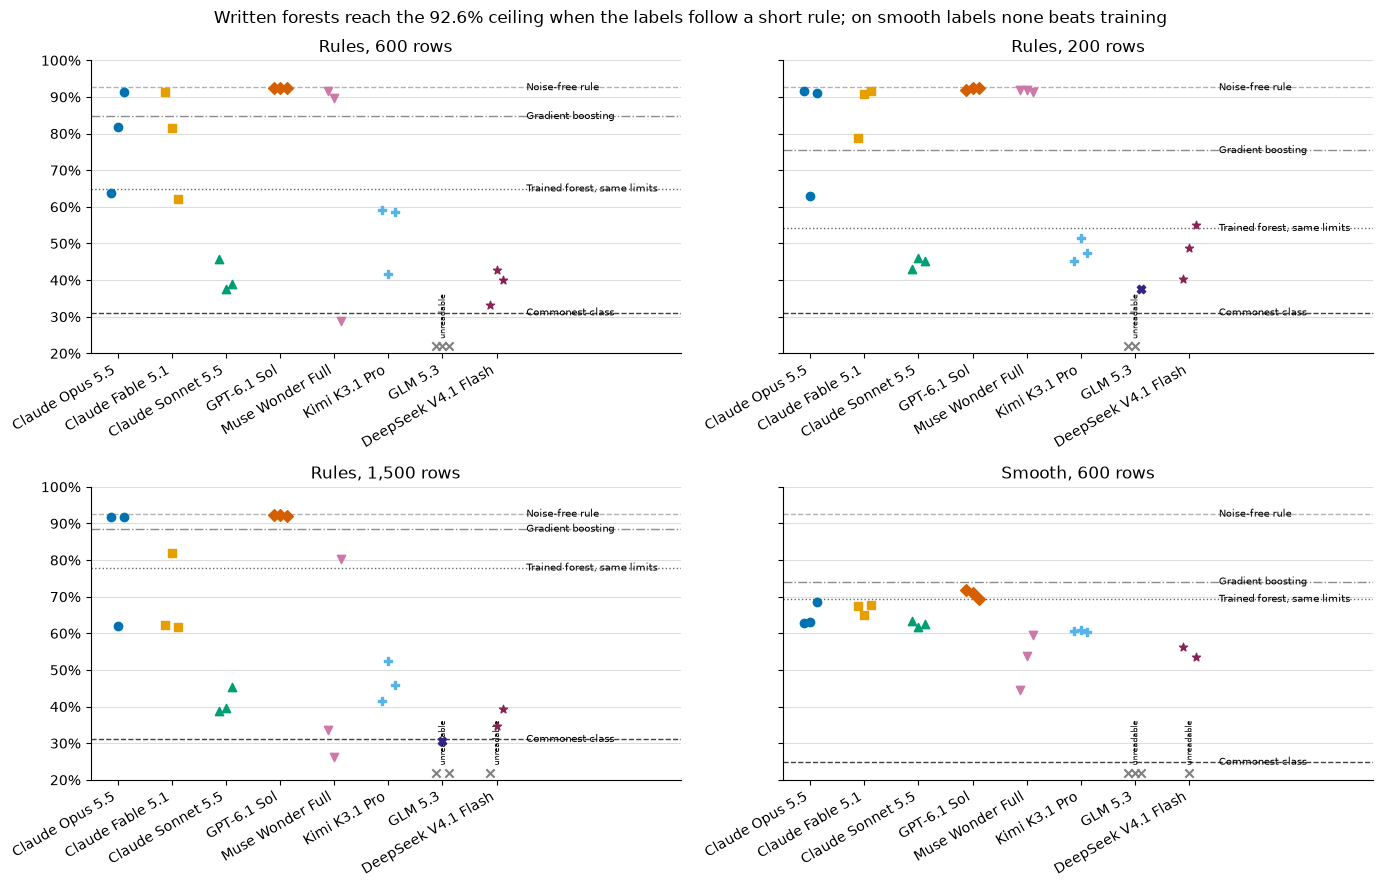

In [24]:
def plot_forest_accuracy(title="Forest accuracy"):
    fig, axs = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    for ax, task in zip(axs.flat, FOREST_TASKS):
        for i, model in enumerate(MODEL_ORDER):
            s = results[(results.task == task) & (results.model == model)]
            for _, r in s.iterrows():
                x = i + (int(r["repeat"]) - 1) * 0.12
                ax.scatter(
                    x,
                    r.score if r.readable else 0.22,
                    color=COLORS[model] if r.readable else "grey",
                    marker=MARKERS[model] if r.readable else "x",
                    zorder=4,
                )
            if (~s.readable).any():
                ax.text(i, 0.245, "unreadable", fontsize=6, rotation=90, ha="center")
        for j, name in enumerate(
            ["Commonest class", "Trained forest, same limits", "Gradient boosting", "Noise-free rule"]
        ):
            v = refs[(refs.task == task) & (refs.reference == name)].score.iloc[0]
            ax.axhline(v, color=str(0.25 + j * 0.15), ls=["--", ":", "-.", "--"][j], lw=1)
            ax.text(7.55, v, name, fontsize=7, va="center")
        ax.set(title=TASK_NAMES[task], ylim=(0.2, 1), xlim=(-0.5, 10.4))
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_xticks(range(8), [MODEL_INFO[m]["label"] for m in MODEL_ORDER], rotation=30, ha="right")
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(fig, "forest_accuracy.png")


plot_forest_accuracy("Written forests reach the 92.6% ceiling when the labels follow a short rule; on smooth labels none beats training")

Each panel is one forest task. Each marker is one written forest, coloured and shaped by model, with the three
requests set slightly apart; a grey cross at the bottom marks an unreadable reply. The horizontal lines are references
trained or computed on the same visible rows: commonest class, the trained forest with the same limits, gradient
boosting, and the noise-free rule at 92.6%.

On the three rules panels the markers split into a cluster at the ceiling line and a cloud below the trained forest.
Sol's orange diamonds sit on the ceiling in all three panels. Opus, Fable and Muse have markers on the ceiling and
others scattered from 26% to 82%. The trained references climb with more rows (the trained forest from 54.2% at 200
rows to 77.9% at 1,500), while the top cluster stays at the ceiling in every panel.

On the smooth panel the cluster is gone. All written forests sit between 44% and 72%, around the trained forest line
(69.4%) and below gradient boosting (74.1%). There is no rule to recognise in that task, only a curved boundary to
approximate with a limited number of boxes, which is what a training program is built to do. The written forests are
not worse at it by much, but they are not better.

What the figure does not show is why a top model fails on a given request; section 7 opens the failed files.

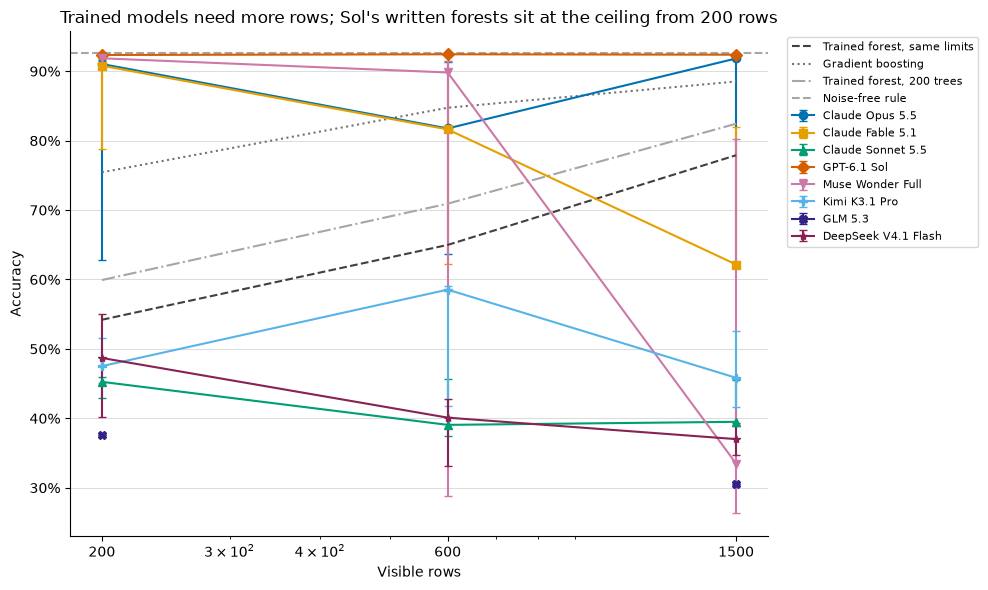

In [25]:
def plot_forest_sample_size(title="Accuracy by visible sample size"):
    fig, ax = plt.subplots(figsize=(10, 6))
    tasks = ["rules-200", "rules-600", "rules-1500"]
    xs = [200, 600, 1500]
    for model in MODEL_ORDER:
        med = []
        lo = []
        hi = []
        for task in tasks:
            s = results[(results.task == task) & (results.model == model) & results.readable].score
            med.append(s.median())
            lo.append(s.min())
            hi.append(s.max())
        med = np.array(med, dtype=float)
        lo = np.array(lo, dtype=float)
        hi = np.array(hi, dtype=float)
        if np.isfinite(med).any():
            ax.errorbar(
                xs,
                med,
                yerr=np.array([med - lo, hi - med]),
                color=COLORS[model],
                marker=MARKERS[model],
                label=MODEL_INFO[model]["label"],
                capsize=3,
            )
    for j, name in enumerate(["Trained forest, same limits", "Gradient boosting", "Trained forest, 200 trees"]):
        vals = [refs[(refs.task == t) & (refs.reference == name)].score.iloc[0] for t in tasks]
        ax.plot(xs, vals, ls=["--", ":", "-."][j], color=str(0.25 + j * 0.2), label=name)
    v = refs[(refs.task == "rules-600") & (refs.reference == "Noise-free rule")].score.iloc[0]
    ax.axhline(v, color=".65", ls="--", label="Noise-free rule")
    ax.set_xscale("log")
    ax.set_xticks(xs, [str(x) for x in xs])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(xlabel="Visible rows", ylabel="Accuracy", title=title)
    ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.tight_layout()
    save_figure(fig, "forest_sample_size.png")


plot_forest_sample_size("Trained models need more rows; Sol's written forests sit at the ceiling from 200 rows")

This chart puts the three rules tasks on one axis of visible rows (200, 600, 1,500, on a log scale). Each coloured line
joins a model's median forest, with a bar from its worst to its best; the grey dashed lines are the trained forest with
the same limits, the 200-tree forest and gradient boosting.

Trained models improve steadily with data: gradient boosting goes from 75.4% to 84.7% to 88.5%, and the trained forest
with the same limits from 54.2% to 65.0% to 77.9%. Sol's line is flat at the ceiling, because with 200 rows it already
writes the rule. More data even hurt some writers: Muse's median fell from 91.9% at 200 rows to 33.5% at 1,500, and
Fable's from 90.8% to 62.2%, while Opus stayed between 81.8% and 91.8%. A longer prompt (60,522 characters at 1,500
rows) means more rows to scan, and the misreads in section 7 are of the kind more rows make likelier: a model
latches onto a pattern in part of the data. With three requests per point, the medians of the inconsistent models
can move by tens of points if one request goes the other way, so the direction of this effect is suggestive, not
established.

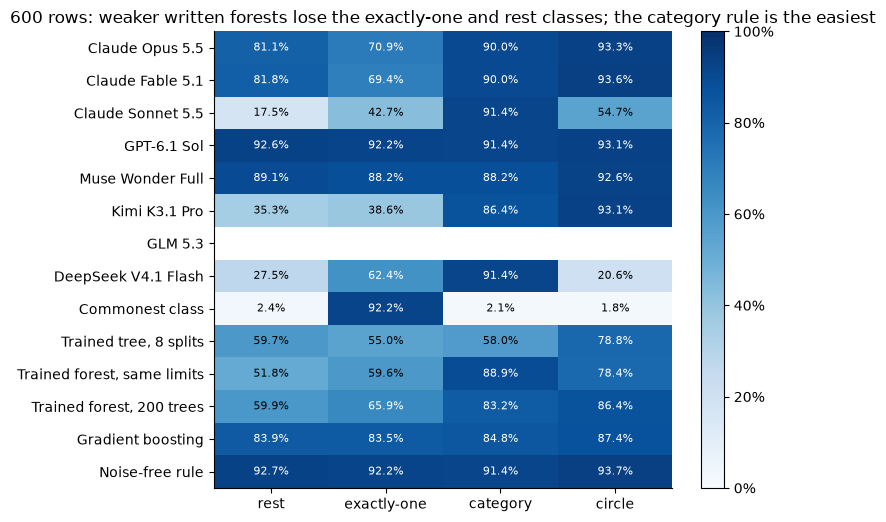

In [26]:
def plot_forest_by_rule(title="Accuracy by true rule"):
    labels = []
    values = []
    for model in MODEL_ORDER:
        s = results[(results.task == "rules-600") & (results.model == model) & results.readable]
        labels.append(MODEL_INFO[model]["label"])
        values.append([s[f"acc_class{i}"].median() for i in range(4)])
    for _, r in refs[refs.task == "rules-600"].iterrows():
        labels.append(r.reference)
        values.append([r[f"acc_class{i}"] for i in range(4)])
    a = np.array(values, dtype=float)
    fig, ax = plt.subplots(figsize=(8, max(5, len(labels) * 0.38)))
    im = ax.imshow(a, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(4), RULE_NAMES)
    ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(4):
            if np.isfinite(a[i, j]):
                ax.text(
                    j,
                    i,
                    f"{a[i, j]:.1%}",
                    ha="center",
                    va="center",
                    color="white" if a[i, j] > 0.6 else "black",
                    fontsize=8,
                )
    fig.colorbar(im, ax=ax, format=PercentFormatter(1))
    ax.set_title(title)
    fig.tight_layout()
    save_figure(fig, "forest_by_rule.png")


plot_forest_by_rule("600 rows: weaker written forests lose the exactly-one and rest classes; the category rule is the easiest")

The heatmap splits accuracy on the 600-row task by which rule produced the hidden row's true class: rest, exactly-one,
category or circle. Each row is a model's median over its readable forests, followed by the references. Darker blue
is higher; the noise-free rule scores about 92% in every column because 7.4% of the labels are noise.

The category rule is the easiest: almost every written forest scores 86% to 91% on it, because a split on the code
x7 and one on x2 describe it completely. The circle separates the groups: Sol, Opus, Fable, Muse and Kimi score 93% on
it, Sonnet 55% and DeepSeek 21%. The exactly-one rule and the rest class are where the top group loses points when it
fails: the median Opus forest scores 70.9% on exactly-one, against 92.2% for Sol. Kimi gets the circle and the
category right but scores 39% on exactly-one and 35% on rest, which is why its forests sit near 59%: it found two of
the three rules.

The trained forest with the same limits shows the opposite pattern: 88.9% on the category rule, 78.4% on the circle,
but 51.8% on rest and 59.6% on exactly-one. A greedy tree finds the exactly-one pattern hard, because neither x3 nor
x4 alone says anything about it, so the first split on either one gains nothing.

## 6. Results: written LSTMs

The LSTM tasks ask for something different from the forests. There is no hidden rule to spot in one view; the
forecaster has to combine a weekly pattern, a trend, promotions and day-to-day noise, and its weights have to do that
through the LSTM's gates.

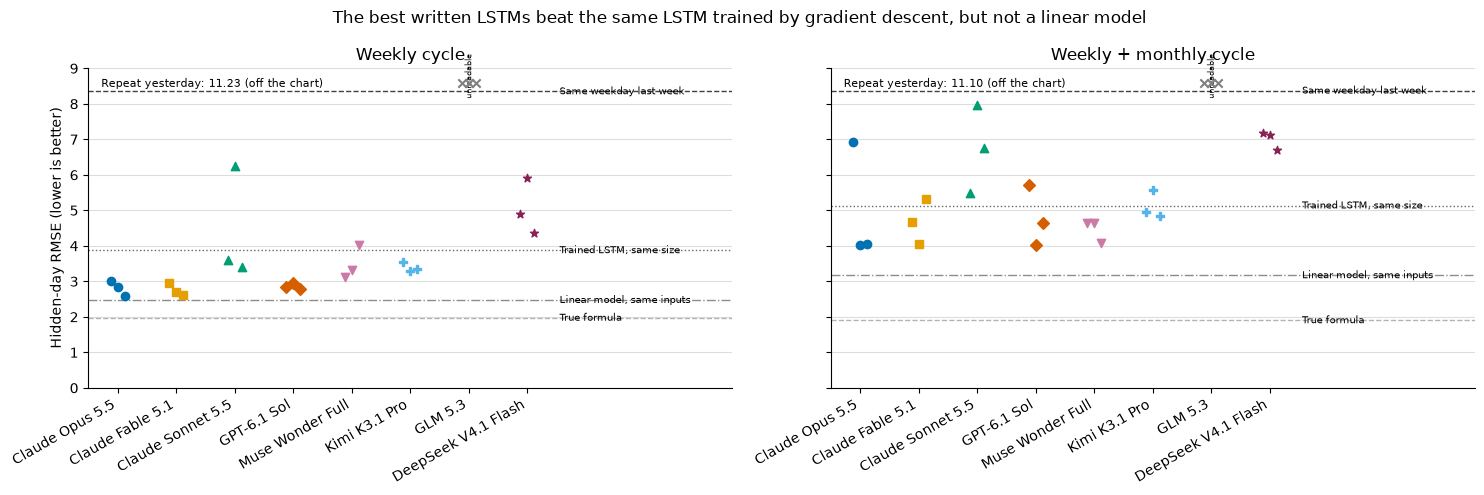

In [27]:
def plot_lstm_rmse(title="LSTM forecast error"):
    fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for ax, task in zip(axs, LSTM_TASKS):
        for i, model in enumerate(MODEL_ORDER):
            s = results[(results.task == task) & (results.model == model)]
            for _, r in s.iterrows():
                ax.scatter(
                    i + (int(r["repeat"]) - 1) * 0.12,
                    r.score if r.readable else 8.6,
                    color=COLORS[model] if r.readable else "grey",
                    marker=MARKERS[model] if r.readable else "x",
                    zorder=4,
                )
            if (~s.readable).any():
                ax.text(i, 8.2, "unreadable", fontsize=6, rotation=90, ha="center")
        for j, name in enumerate(
            ["Same weekday last week", "Trained LSTM, same size", "Linear model, same inputs", "True formula"]
        ):
            v = refs[(refs.task == task) & (refs.reference == name)].score.iloc[0]
            ax.axhline(v, color=str(0.25 + j * 0.15), ls=["--", ":", "-.", "--"][j], lw=1)
            ax.text(7.55, v, name, fontsize=7, va="center")
        v = refs[(refs.task == task) & (refs.reference == "Repeat yesterday")].score.iloc[0]
        ax.text(
            0.02, 0.97, f"Repeat yesterday: {v:.2f} (off the chart)", transform=ax.transAxes, va="top", fontsize=8
        )
        ax.set(title=TASK_NAMES[task], ylim=(0, 9), xlim=(-0.5, 10.5))
        ax.set_xticks(range(8), [MODEL_INFO[m]["label"] for m in MODEL_ORDER], rotation=30, ha="right")
    axs[0].set_ylabel("Hidden-day RMSE (lower is better)")
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(fig, "lstm_rmse.png")


plot_lstm_rmse("The best written LSTMs beat the same LSTM trained by gradient descent, but not a linear model")

Each marker is one written LSTM's RMSE on the 140 hidden days; lower is better. The horizontal lines are same weekday
last week, the trained LSTM with the same size, the linear model on the same inputs and the true formula. Repeat
yesterday (11.2 on both tasks) is off the chart.

On the weekly task the markers from Opus, Fable and Sol sit between 2.60 and 3.02, below the trained LSTM (3.87) and
above the linear model (2.47), with the floor at 1.97. Muse, Kimi and Sonnet mostly sit between 3.1 and 3.6, also
better than the trained LSTM, and DeepSeek's three are worse (4.4 to 5.9). Every readable LSTM beats both rules of
thumb by a wide margin.

On the two-cycle task every marker moves up. The best are Sol, Opus, Muse and Fable at 4.02 to 4.08, still better than
the trained LSTM (5.13), but further from the linear model (3.17) and the floor (1.90). The added pay cycle is what
separates them, as the next chart shows.

The trained LSTM is a fair reference but not a strong one. Its 36 candidates (six starting points, six stopping
points) scored between 2.57 and 10.1 on the weekly hidden days, and the choice made on held-out visible weeks landed
at 3.87. Training a network this small by gradient descent on 500 days is fragile; the written LSTMs avoid that
fragility by not fitting at all.

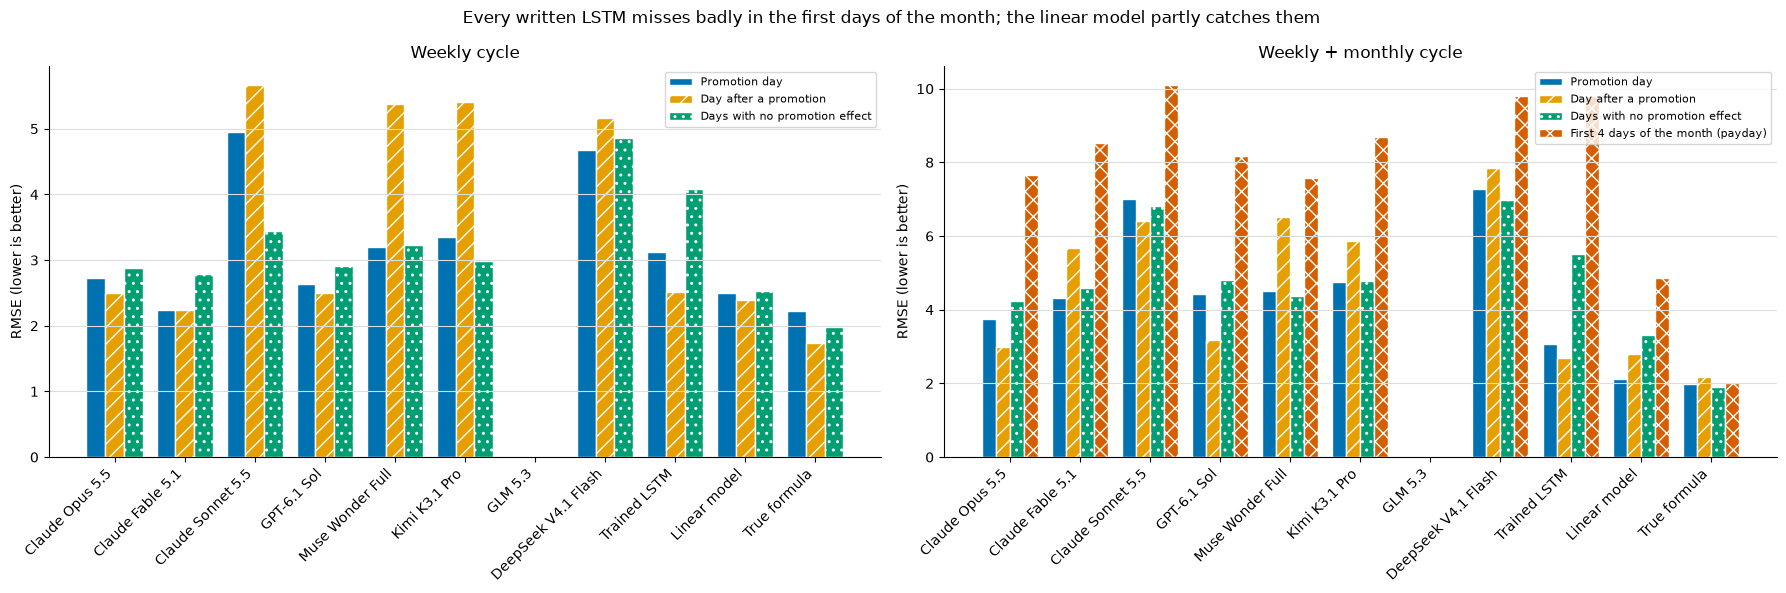

In [28]:
def plot_lstm_day_types(title="Forecast error by day type"):
    fig, axs = plt.subplots(1, 2, figsize=(18, 6))
    for ax, task in zip(axs, LSTM_TASKS):
        names = [MODEL_INFO[m]["label"] for m in MODEL_ORDER] + ["Trained LSTM", "Linear model", "True formula"]
        cols = ["rmse_promo_day", "rmse_day_after_promo", "rmse_other_days"] + (
            ["rmse_payday"] if task == "two-cycles" else []
        )
        labels = ["Promotion day", "Day after a promotion", "Days with no promotion effect"] + (
            ["First 4 days of the month (payday)"] if task == "two-cycles" else []
        )
        x = np.arange(len(names))
        width = 0.8 / len(cols)
        colours, hatches = ["#0072B2", "#E69F00", "#009E73", "#D55E00"], ["", "//", "..", "xx"]
        for j, (col, label) in enumerate(zip(cols, labels)):
            vals = [
                results[(results.task == task) & (results.model == m) & results.readable][col].median()
                for m in MODEL_ORDER
            ]
            vals += [
                refs[(refs.task == task) & (refs.reference == n)][col].iloc[0]
                for n in ["Trained LSTM, same size", "Linear model, same inputs", "True formula"]
            ]
            ax.bar(x + (j - (len(cols) - 1) / 2) * width, vals, width, label=label, color=colours[j],
                   hatch=hatches[j], edgecolor="white")
        ax.set_xticks(x, names, rotation=45, ha="right")
        ax.set(title=TASK_NAMES[task], ylabel="RMSE (lower is better)")
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(fig, "lstm_day_types.png")


plot_lstm_day_types("Every written LSTM misses badly in the first days of the month; the linear model partly catches them")

The bars split each model's median RMSE by kind of day: promotion days, the day after a promotion, days with no
promotion effect, and for the two-cycle task the first four days of each 30-day month, when the payday lift happens.

On the weekly task the top written LSTMs do about as well on promotion days as on other days (Fable 2.23 on promotion
days, Sol 2.63), so they handle the lift. Muse, Kimi, Sonnet and DeepSeek do worse on the day after a promotion
(medians 5.2 to 5.7), because several of their files ignore the dip; section 7 shows those files' weight for
yesterday's promotion near zero.

On the two-cycle task the payday bars stand out. The written LSTMs miss the first four days of the month by 7.0 to
12.6 (medians by model 7.6 to 10.1), against 4.86 for the linear model and 2.02 for the true formula. The trained LSTM
misses them as badly (9.81).
The linear model catches part of the pay cycle because one of its inputs is the value 30 days back, inside the 35-day
window, and least squares gives it a weight (0.4); no written LSTM puts weight there.

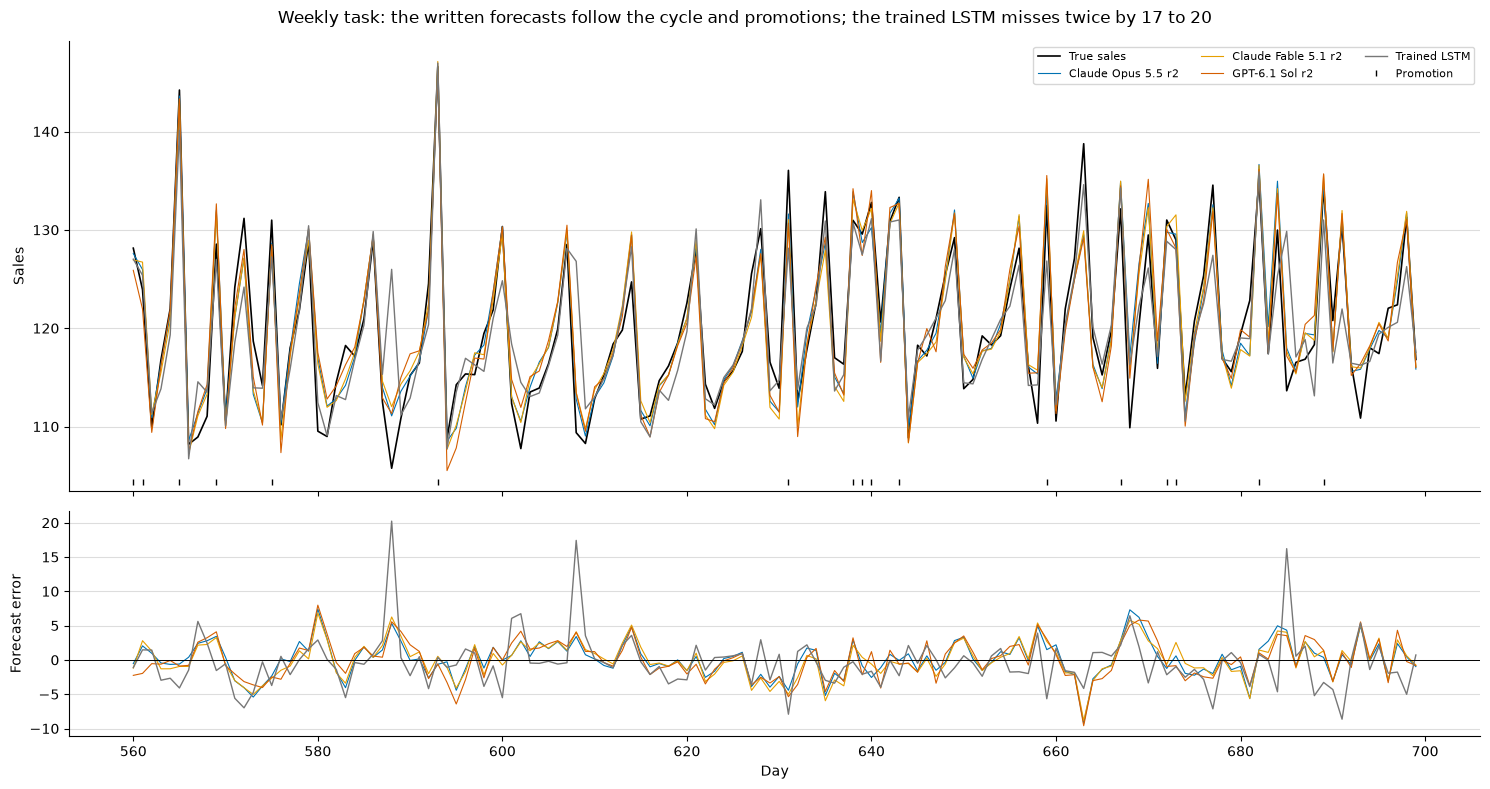

In [29]:
def plot_lstm_traces(picks=None, title="Weekly hidden-day forecasts"):
    if picks is None:
        picks = chosen_best("weekly", ["opus", "fable", "sol"])
    picks = [tuple(p) for p in picks if tuple(p) in loaded and p[0] == "weekly"]
    d = lstm_data["weekly"]
    days = np.arange(N_VIS, N_DAYS)
    truth = d["y"][N_VIS:]
    fig, (ax, err) = plt.subplots(2, 1, figsize=(15, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax.plot(days, truth, color="black", lw=1.2, label="True sales")
    for task, model, repeat in picks:
        pred = (
            20
            * lstm_batch(loaded[(task, model, repeat)], lstm_windows(d["y"], d["promo"], d["window"], N_VIS, N_DAYS))
            + 100
        )
        label = f"{MODEL_INFO[model]['label']} r{repeat}"
        ax.plot(days, pred, color=COLORS[model], lw=0.8, label=label)
        err.plot(days, pred - truth, color=COLORS[model], lw=0.8, label=label)
    pred = ref_preds[("weekly", "Trained LSTM, same size")]
    ax.plot(days, pred, color="#777777", lw=1, label="Trained LSTM")
    err.plot(days, pred - truth, color="#777777", lw=1, label="Trained LSTM")
    ax.plot(
        days[d["promo"][N_VIS:] == 1],
        np.full(int(d["promo"][N_VIS:].sum()), 0.02),
        "|",
        transform=ax.get_xaxis_transform(),
        color="black",
        markersize=5,
        label="Promotion",
    )
    err.axhline(0, color="black", lw=0.7)
    ax.set_ylabel("Sales")
    err.set(ylabel="Forecast error", xlabel="Day")
    ax.legend(fontsize=8, ncol=3)
    fig.suptitle(title)
    fig.tight_layout()
    save_figure(fig, "lstm_traces.png")


plot_lstm_traces(title="Weekly task: the written forecasts follow the cycle and promotions; the trained LSTM misses twice by 17 to 20")

The upper panel shows the true weekly sales over the 140 hidden days (black) with the best readable LSTM from Opus,
Fable and Sol and the trained LSTM (grey); ticks at the bottom mark promotion days. The lower panel shows each
forecast's error.

The written forecasts follow the weekly rhythm and the promotion spikes closely, and their errors move together: on
days where one misses, the others miss by about the same amount in the same direction. Those shared misses are the
day's noise, which no forecaster can predict. The trained LSTM's errors are different: it is usually close, but on
days 588 and 608, two days with sales about 5 below the usual pattern, it overshoots by 20 and 17, while the written
forecasts overshoot by 3 to 6. RMSE weighs such large misses heavily, and these two days are a large part of why the
trained LSTM scores 3.87.

## 7. What the written models encode

A written model is a program, so it can be read. This section opens the files: where the forests put their
boundaries, which features they ask about, and which past days the LSTMs read.

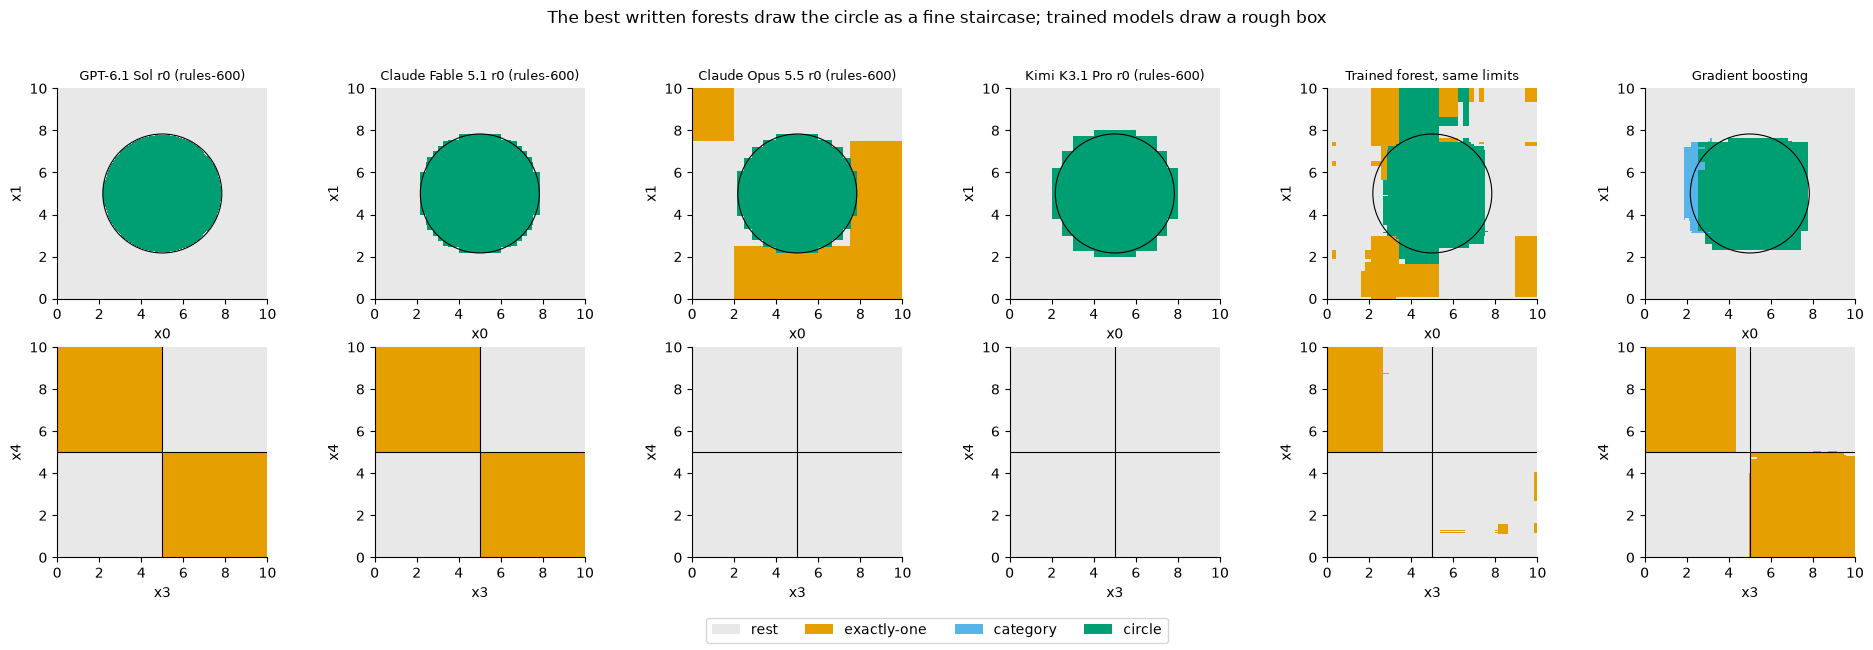

In [30]:
def plot_forest_maps(picks=None, title="Forest decision maps"):
    if picks is None:
        picks = chosen_best("rules-600", ["opus", "fable", "sonnet", "sol"])
    picks = [tuple(p) for p in picks if tuple(p) in loaded and p[0] not in LSTM_TASKS]
    d = forest_data["rules-600"]
    models = [
        RandomForestClassifier(MAX_TREES, max_depth=MAX_SPLITS, random_state=0),
        HistGradientBoostingClassifier(random_state=0),
    ]
    for m in models:
        m.fit(d["Xv"], d["yv"])
    names = [f"{MODEL_INFO[m]['label']} r{r} ({t})" for t, m, r in picks] + [
        "Trained forest, same limits",
        "Gradient boosting",
    ]
    fig, axs = plt.subplots(2, len(names), figsize=(3.2 * len(names), 6.5), squeeze=False)
    grid = np.linspace(0, 10, 200)
    xx, yy = np.meshgrid(grid, grid)
    from matplotlib.colors import ListedColormap

    cmap = ListedColormap(["#e8e8e8", "#e69f00", "#56b4e9", "#009e73"])
    for row in range(2):
        X = np.tile([0, 0, 2, 2, 2, 5, 5, 0], (xx.size, 1)).astype(float)
        if row == 0:
            X[:, 0] = xx.ravel()
            X[:, 1] = yy.ravel()
        else:
            X[:, 3] = xx.ravel()
            X[:, 4] = yy.ravel()
        predictions = [forest_predict_all(loaded[p], X) for p in picks] + [m.predict(X) for m in models]
        for col, pred in enumerate(predictions):
            ax = axs[row, col]
            ax.imshow(
                pred.reshape(xx.shape),
                origin="lower",
                extent=(0, 10, 0, 10),
                cmap=cmap,
                vmin=-0.5,
                vmax=3.5,
                interpolation="nearest",
            )
            ax.grid(False)
            if row == 0:
                ax.add_patch(Circle((5, 5), np.sqrt(8), fill=False, color="black", lw=0.8))
            else:
                ax.axvline(5, color="black", lw=0.8)
                ax.axhline(5, color="black", lw=0.8)
            ax.set(xlabel="x0" if row == 0 else "x3", ylabel="x1" if row == 0 else "x4")
            if row == 0:
                ax.set_title(names[col], fontsize=9)
    fig.legend(handles=[Patch(facecolor=cmap(i), label=RULE_NAMES[i]) for i in range(4)], loc="lower center", ncol=4)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.06, 1, 0.95))
    save_figure(fig, "forest_maps.png")


plot_forest_maps(
    picks=[("rules-600", "sol", 0), ("rules-600", "fable", 0), ("rules-600", "opus", 0), ("rules-600", "kimi", 0)],
    title="The best written forests draw the circle as a fine staircase; trained models draw a rough box",
)

Each column is one forest; the last two are the trained forest with the same limits and gradient boosting, refit on
the same 600 rows. The top row colours the plane of x0 and x1 by predicted class, with the other features held where
only the circle rule can apply (x2 = x3 = x4 = 2, x7 = 0); the black circle is the true boundary. The bottom row does
the same for x3 and x4, holding x0 = x1 = 0 so only the exactly-one rule can apply; the black lines are the true
boundaries at 5.

Sol's forest (92.4%) draws the circle as a staircase so fine it looks smooth, and the exactly-one quarters exactly at 5.
Fable's (91.5%) draws a coarser staircase with visible steps and the same quarters. Opus's first forest (63.7%)
draws a good circle, but its bottom row is blank: it found no exactly-one pattern in x3 and x4, and instead marked
corner regions of the x0 and x1 plane as exactly-one (the orange patches in the top row). That is a misread of which
features carry the rule. Kimi's forest (59.1%) draws a circle and no exactly-one region at all.

The trained forest draws a rough box around the circle with ragged edges, and patches scattered where a few noisy
rows happened to sit. Gradient boosting draws a tighter box and finds the exactly-one quarters, though its boundary
drifts off 5. Both are what a training program does with 600 noisy rows: it fits where the data is, without knowing the
shape is a circle.

In [31]:
reading_rows = []
for _, r in results[
    (results.family == "forest") & results.task.str.startswith("rules") & results.readable
].iterrows():
    obj = loaded[(r.task, r.model, int(r["repeat"]))]
    splits = [n for tree in obj["trees"] for n in tree["nodes"] if "leaf" not in n]
    distances = [abs(n["threshold"] - 5) for n in splits if n["feature"] in (3, 4)]
    reading_rows.append(
        dict(
            model=r.model,
            task=r.task,
            repeat=int(r["repeat"]),
            accuracy=r.accuracy,
            trees=r.trees,
            nodes=r.nodes,
            max_depth=r.max_depth,
            circle_splits=r.splits_x0 + r.splits_x1,
            exactly_one_splits=r.splits_x3 + r.splits_x4,
            category_splits=r.splits_x2 + r.splits_x7,
            irrelevant_splits=r.splits_x5 + r.splits_x6,
            median_threshold_distance_from_5=np.median(distances) if distances else np.nan,
            x7_thresholds=sorted({n["threshold"] for n in splits if n["feature"] == 7}),
        )
    )
forest_reading = pd.DataFrame(
    reading_rows,
    columns=[
        "model",
        "task",
        "repeat",
        "accuracy",
        "trees",
        "nodes",
        "max_depth",
        "circle_splits",
        "exactly_one_splits",
        "category_splits",
        "irrelevant_splits",
        "median_threshold_distance_from_5",
        "x7_thresholds",
    ],
).sort_values(["task", "accuracy"])
print("\nFOREST READING\n", forest_reading.to_string(index=False))


FOREST READING
    model       task  repeat  accuracy  trees  nodes  max_depth  circle_splits  exactly_one_splits  category_splits  irrelevant_splits  median_threshold_distance_from_5   x7_thresholds
    muse rules-1500       1    0.2632   14.0  194.0        3.0           21.0                22.0             27.0               20.0                             0.000      [1.5, 2.5]
     glm rules-1500       1    0.3050   15.0  193.0        4.0           14.0                28.0             22.0               25.0                             0.000 [0.5, 1.5, 2.5]
    muse rules-1500       0    0.3348    5.0  115.0        6.0           12.0                15.0             20.0                8.0                             2.000 [0.5, 1.5, 2.5]
deepseek rules-1500       1    0.3476   20.0  112.0        2.0           13.0                11.0              8.0               14.0                             0.000 [0.5, 1.5, 2.5]
  sonnet rules-1500       0    0.3884    3.0   45.0        4.0 

The table counts, for every readable rules-task forest, the questions asked about each group of features: x0 and x1
(the circle), x3 and x4 (exactly-one), x2 and x7 (category) and x5 and x6, which the rule never uses. It also gives the
median distance of the x3 and x4 thresholds from 5 and the distinct thresholds used on the category code.

The forests at the ceiling share one design. They spend most of their questions on x0 and x1 (25 to 252 questions,
a staircase), 3 on the category rule (x7 at 1.5 and 2.5 to isolate code 2, then x2 at 4), 3 to 18 on exactly-one with
thresholds at or within 0.03 of 5, and none on x5 or x6. That is the generating rule,
written as trees: usually one or two circle trees and one rule tree, with the circle trees outvoting the rule tree,
as in the worked example.

The failures differ from each other. Opus's three forests below 64% and most of Kimi's spend no questions on x3 and x4
at all; they dropped the exactly-one rule. Fable's 62.2% forest on 600 rows asks 64 questions about x5 and x6, which
carry nothing, so it built structure on noise. Muse's 28.9% forest has 20 trees only two questions deep, with
questions spread over every feature, the look of a forest built without finding any rule. The forests of Sonnet and
DeepSeek are mostly small and too coarse to draw a circle: Sonnet spends 0 to 32 questions on the circle, against 49 or
more in every ceiling forest from Opus, Fable and Sol.

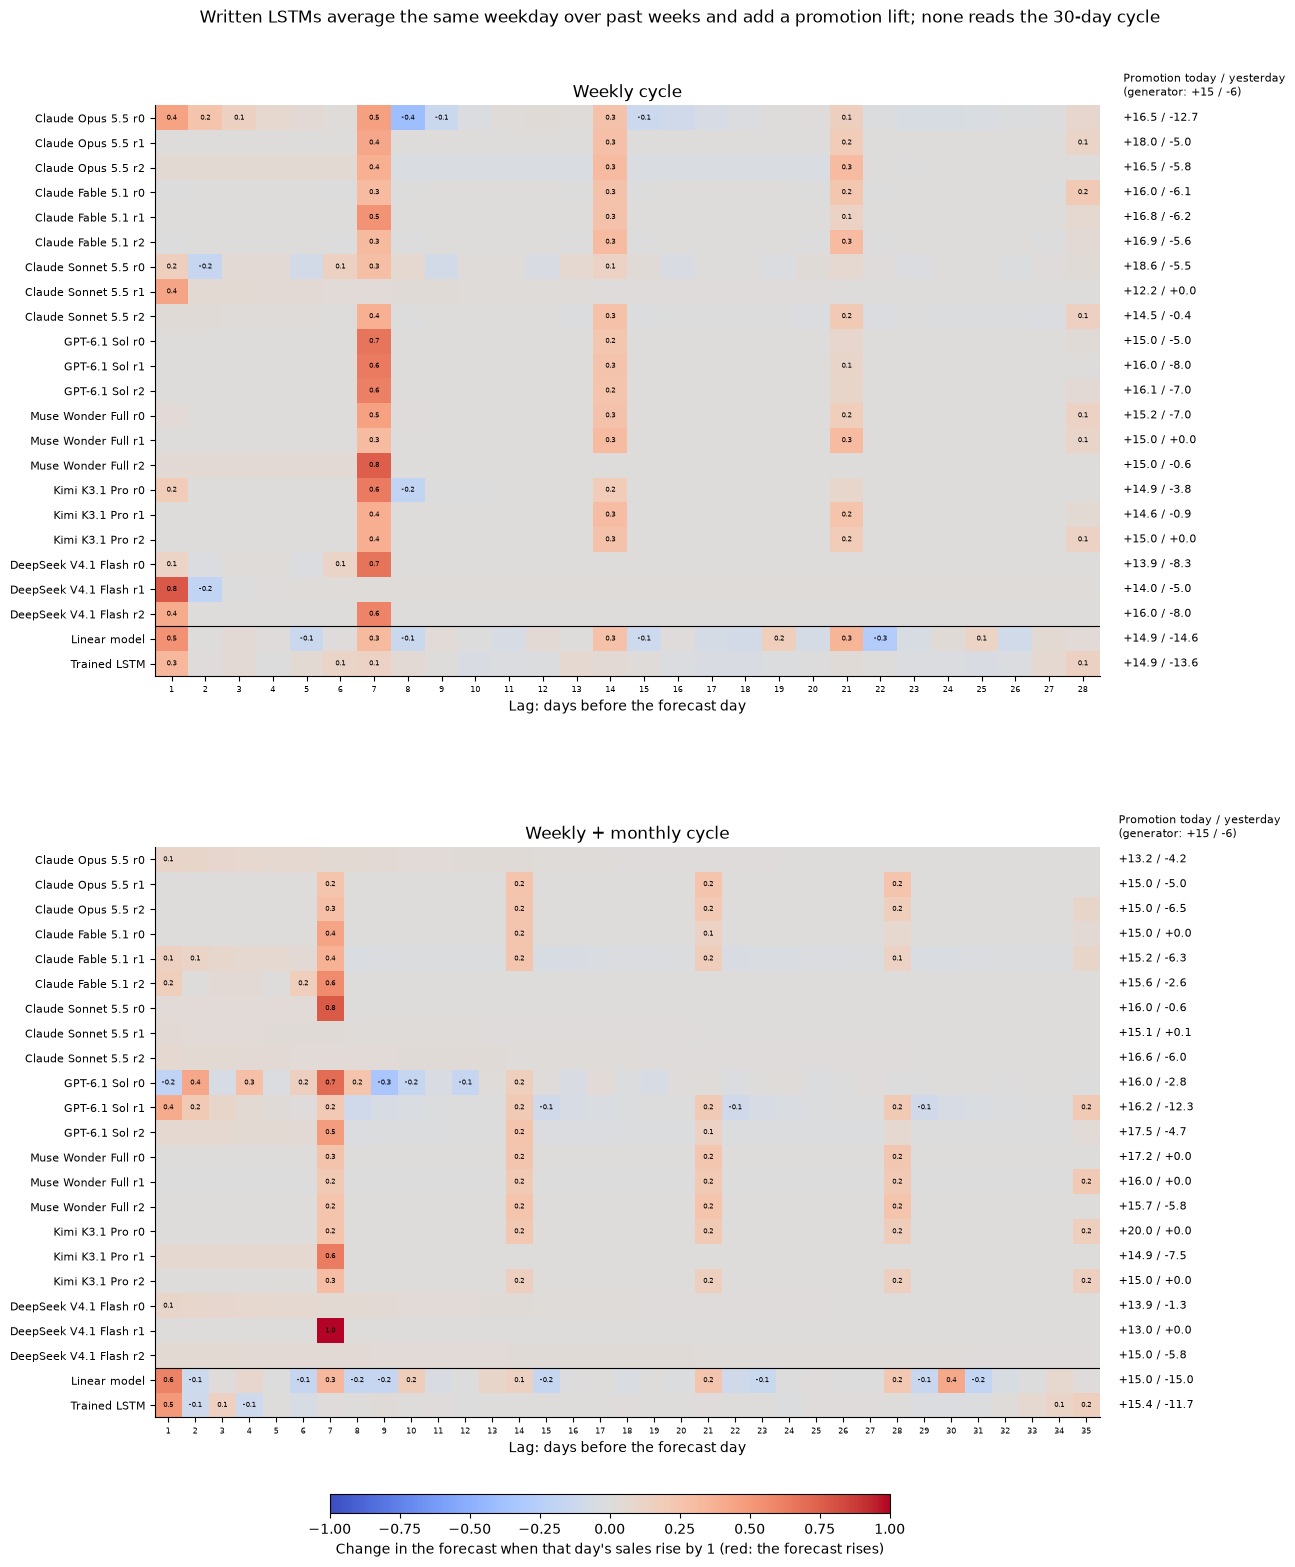

In [32]:
def plot_lstm_lag_profiles(title="LSTM lag and promotion profiles"):
    fig, axs = plt.subplots(2, 1, figsize=(14, 16))
    for ax, task in zip(axs, LSTM_TASKS):
        w = LSTM_TASKS[task]["window"]
        labels = []
        data = []
        flags = []
        for model in MODEL_ORDER:
            for _, r in (
                results[(results.task == task) & (results.model == model) & results.readable]
                .sort_values("repeat")
                .iterrows()
            ):
                labels.append(f"{r.label} r{int(r['repeat'])}")
                data.append([r[f"lag_{i}"] for i in range(1, w + 1)])
                flags.append((r.promo_today, r.promo_yesterday))
        extra = lstm_extra[task]
        labels += ["Linear model", "Trained LSTM"]
        data += [extra["linear_lags"], extra["trained_profile"]["lags"]]
        d = lstm_data[task]
        Xv = lstm_windows(d["y"], d["promo"], w, w, N_VIS)
        flat = np.c_[Xv.reshape(len(Xv), -1), np.ones(len(Xv))]
        coef = np.linalg.lstsq(flat, (d["y"][w:N_VIS] - 100) / 20, rcond=None)[0]
        flags += [
            (20 * coef[2 * (w - 1) + 1], 20 * coef[2 * (w - 2) + 1]),
            (extra["trained_profile"]["promo_today"], extra["trained_profile"]["promo_yesterday"]),
        ]
        a = np.asarray(data, dtype=float)
        im = ax.imshow(a, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(w), range(1, w + 1), fontsize=6)
        ax.set_yticks(range(len(labels)), labels, fontsize=8)
        for i in range(len(labels)):
            for j in range(w):
                if abs(a[i, j]) >= 0.1:
                    ax.text(j, i, f"{a[i, j]:.1f}", ha="center", va="center", fontsize=5)
            flag_text = " / ".join(f"{x:+.1f}" if np.isfinite(x) else "n/a" for x in flags[i])
            ax.text(w + 0.2, i, flag_text, va="center", fontsize=8, clip_on=False)
        ax.text(w + 0.2, -0.9, "Promotion today / yesterday\n(generator: +15 / -6)", fontsize=8, clip_on=False)
        ax.axhline(len(labels) - 2.5, color="black", lw=0.8)
        ax.set(xlabel="Lag: days before the forecast day", title=TASK_NAMES[task])
    fig.subplots_adjust(right=0.8, hspace=0.3, bottom=0.1, top=0.92)
    cax = fig.add_axes([0.25, 0.04, 0.4, 0.012])
    fig.colorbar(im, cax=cax, orientation="horizontal",
                 label="Change in the forecast when that day's sales rise by 1 (red: the forecast rises)")
    fig.suptitle(title)
    save_figure(fig, "lstm_lag_profiles.png")


plot_lstm_lag_profiles("Written LSTMs average the same weekday over past weeks and add a promotion lift; none reads the 30-day cycle")

Each row is one readable LSTM (or reference) and each column a day in its input window, counted back from the day
being forecast. The colour is the average change in the forecast when that one day's sales rise by 1, measured by
nudging the input on every hidden day and running the network: a weight of 0.5 at lag 7 means the forecast moves by
half of any change in last week's sales on the same weekday. The numbers on the right are the change in the forecast
when the promotion flag of the forecast day, or of yesterday, is switched on; the generator uses +15 and -6.

Almost every good written LSTM reads the same weekday from earlier weeks: lags 7, 14 and 21, sometimes 28, with
weights that sum to about 1. Fable's 2.63 weekly LSTM reads lags 7, 14 and 21 at 0.31 each, an average of the last
three same weekdays, which smooths out each week's noise. Sol's put 0.6 on lag 7 and 0.25 on lag 14. Several files hit
the promotion effect almost exactly: Opus's 2.60 file adds +16.5 for a promotion today and -5.8 after one yesterday,
against the true +15 and -6.

The pilot found two ways of building this inside an LSTM, and the full study found more. Fable's first weekly file
wires pairs of memory units into rotations at one, two and three cycles a week, a set of oscillators that track the
weekly pattern; its forget gates are switched off and its inputs are scaled down so the gates behave linearly. Other
files hold the value from a week ago in a memory cell opened only at the right step. In this chart the different
constructions look alike, because they compute nearly the same function.

What the best written files do not read is lag 1, yesterday. The noise in these series carries 0.6 of each day's
surprise into the next, so yesterday's value carries information. The linear model puts 0.5 on lag 1 and the trained
LSTM 0.3. A forecaster that knew the generator's pattern exactly but ignored this carry-over would score 2.29 on the
weekly task; the true formula, which uses it, scores 1.97. The written files treat each day's noise as unpredictable
and give up that part of the error, on top of their small errors in the pattern itself.

On the two-cycle task no written LSTM puts more than 0.05 on lag 30, where the pay cycle would show; Opus, Fable and
Muse average lags 7, 14, 21 and 28 as before. The linear model's row has 0.4 at lag 30.

In [33]:
reading_rows = []
for _, r in results[(results.family == "lstm") & results.readable].iterrows():
    w = LSTM_TASKS[r.task]["window"]
    vals = np.array([r[f"lag_{i}"] for i in range(1, w + 1)], float)
    top = np.argsort(-np.abs(vals))[:3]
    reading_rows.append(
        dict(
            model=r.model,
            task=r.task,
            repeat=int(r["repeat"]),
            rmse=r.rmse,
            top_lags=", ".join(f"{i + 1}: {vals[i]:.2f}" for i in top),
            sum_lag_weights=vals.sum(),
            promo_today=r.promo_today,
            promo_yesterday=r.promo_yesterday,
            visible_rmse=r.visible_rmse,
        )
    )
lstm_reading = pd.DataFrame(
    reading_rows,
    columns=[
        "model",
        "task",
        "repeat",
        "rmse",
        "top_lags",
        "sum_lag_weights",
        "promo_today",
        "promo_yesterday",
        "visible_rmse",
    ],
).sort_values(["task", "rmse"])
print("\nLSTM READING\n", lstm_reading.to_string(index=False))


LSTM READING
    model       task  repeat     rmse                     top_lags  sum_lag_weights  promo_today  promo_yesterday  visible_rmse
     sol two-cycles       1 4.017092    1: 0.40, 7: 0.21, 2: 0.20         0.999935    16.180096       -12.324079      3.960957
    opus two-cycles       1 4.020064 28: 0.25, 14: 0.25, 21: 0.25         0.999363    15.000054        -5.000001      4.102764
    opus two-cycles       2 4.057523  7: 0.28, 14: 0.24, 21: 0.21         0.999896    15.000001        -6.500000      4.117580
   fable two-cycles       1 4.065511  7: 0.36, 14: 0.24, 21: 0.17         0.999140    15.203811        -6.329267      4.112761
    muse two-cycles       2 4.075894  7: 0.25, 14: 0.25, 28: 0.25         0.986429    15.661786        -5.767329      4.200812
     sol two-cycles       2 4.648746  7: 0.48, 14: 0.24, 21: 0.13         1.010921    17.500000        -4.736533      4.856151
    muse two-cycles       0 4.649288  7: 0.25, 14: 0.24, 21: 0.23         0.952556    17.173117 

The table lists, for each readable LSTM, the three lags with the largest weight, the sum of all lag weights (1 means
the forecast moves one for one with the general level of sales), the two promotion effects, and the RMSE on the visible
days. Sorted by hidden RMSE, the best rows read lags 7, 14 and 21 and carry promotion effects near +15 and -6. The worst
rows read only the last few days (Sonnet's 6.26 file weights lags 1 to 3, DeepSeek's 5.92 file puts 0.78 on lag 1)
or put all the weight on lag 7 (DeepSeek's 7.12, which is "same weekday last week" plus a promotion lift).

## 8. Unreadable replies and wrong answers

Two different things can go wrong with a written file. It can load and score badly, which says something about the
model's skill at the task, or it can fail to load at all, which often says more about the format. This section
separates them.

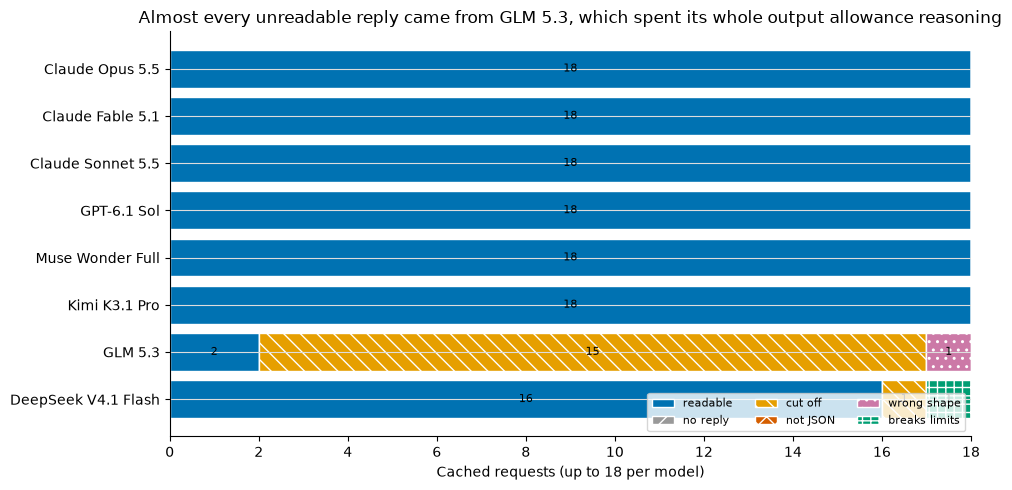

In [34]:
def plot_format_failures(title="Reply readability and format failures"):
    fig, ax = plt.subplots(figsize=(10, 5))
    left = np.zeros(len(MODEL_ORDER))
    names = ["readable"] + FAILURE_KINDS
    colors = ["#0072B2", "#999999", "#E69F00", "#D55E00", "#CC79A7", "#009E73"]
    hatches = ["", "//", "\\\\", "xx", "..", "++"]
    for name, color, hatch in zip(names, colors, hatches):
        counts = np.array(
            [
                int(results[results.model == m].readable.sum())
                if name == "readable"
                else int(((results.model == m) & (results.failure == name)).sum())
                for m in MODEL_ORDER
            ]
        )
        ax.barh(range(8), counts, left=left, color=color, hatch=hatch, edgecolor="white", label=name)
        for i, c in enumerate(counts):
            if c:
                ax.text(left[i] + c / 2, i, str(c), ha="center", va="center", fontsize=8)
        left += counts
    ax.set_yticks(range(8), [MODEL_INFO[m]["label"] for m in MODEL_ORDER])
    ax.invert_yaxis()
    ax.set(xlabel="Cached requests (up to 18 per model)", title=title, xlim=(0, max(18, left.max())))
    ax.legend(ncol=3, fontsize=8, loc="lower right")
    fig.tight_layout()
    save_figure(fig, "format_failures.png")


plot_format_failures("Almost every unreadable reply came from GLM 5.3, which spent its whole output allowance reasoning")

Each bar is one model's 18 requests: readable (blue), then each kind of unreadable reply.

Six models returned 18 readable files out of 18. GLM 5.3 returned 2: in 15 requests it used the whole 128,000-token
output allowance reasoning and was cut off before writing anything, and once it wrote an LSTM with 33 rows in a matrix
that needs 32. Its reasoning text is careful, not looping; on the weekly task it ran to 277,000 characters of checking
gate values one by one before the allowance ran out. DeepSeek V4.1 Flash was cut off once and once wrote a 21-tree
forest when 20 was the limit. These failures say little about whether the two models could have written the rule;
the two readable GLM forests scored 30.5% and 37.6%, in line with the weaker group.

No reply needed the lenient parser: every reply that failed did so for a reason other than surrounding text or
Markdown.

Two parsing decisions affect what counts as readable, and both were made after some results had been seen (see
`data/PROTOCOL.md`). The next cell shows their effect.

In [35]:
def median_by(frame, column):
    return frame.groupby(["task", "model"])[column].median().unstack("model").reindex(columns=MODEL_ORDER)


forest_rows = results[results.family == "forest"].copy()
print("Forests with a node shared by two parents (readable under the prompt's rules, not under a tree-only rule):")
print(forest_rows[forest_rows.shared_nodes][["task", "model", "repeat", "score"]].to_string(index=False))
print("\nMedian forest accuracy under the tree-only rule (shared-node forests counted as unreadable):")
print((100 * median_by(forest_rows, "score_tree_only")).round(1).to_string())

print("\nReplies that ran past 128,000 output tokens through Claude Code's automatic continuation:")
print(results[results.over_allowance][["task", "model", "repeat", "output_tokens", "messages", "score"]].to_string(index=False))
capped = results.copy()
capped.loc[capped.over_allowance, "score"] = np.nan
changed = capped[capped.task.isin(results[results.over_allowance].task.unique())]
print("\nMedians for those tasks if the two replies counted as cut off:")
print(median_by(changed, "score").round(3).to_string())

Forests with a node shared by two parents (readable under the prompt's rules, not under a tree-only rule):
      task model  repeat  score
 rules-600  kimi       0 0.5912
 rules-600  kimi       2 0.5854
 rules-200  kimi       2 0.4752
rules-1500  muse       2 0.8022
smooth-600   sol       0 0.7182
smooth-600   sol       1 0.7108
smooth-600   sol       2 0.6948

Median forest accuracy under the tree-only rule (shared-node forests counted as unreadable):
model       opus  fable  sonnet   sol  muse  kimi   glm  deepseek
task                                                             
rules-1500  91.8   62.2    39.5  92.4  29.9  45.8  30.5      37.0
rules-200   91.0   90.8    45.3  92.3  91.9  48.3  37.6      48.7
rules-600   81.8   81.6    39.1  92.4  89.8  41.8   NaN      40.1
smooth-600  63.1   67.6    62.4   NaN  53.8  60.5   NaN      55.0

Replies that ran past 128,000 output tokens through Claude Code's automatic continuation:
      task model  repeat  output_tokens  messages  score

First, seven forests point two parents at the same node: three from Kimi, one from Muse and all three of Sol's
smooth-task forests. The prompt does not forbid this and the inference code runs it, so they count as readable. Under
the stricter rule of the pilot's loader, which required each node to have one parent, Sol would have no readable
smooth-task forest, and the best smooth-task median would be Fable's 67.6% instead of Sol's 71.1%. On the rules tasks
the stricter rule would lower Kimi's 600-row median from 58.5% to 41.8% and Muse's 1,500-row median from 33.5% to
29.9%, both within the weaker group of results.

Second, one Fable forest arrived in two messages, because Claude Code continues a reply that reaches the per-message
cap; the notebook joins them. That reply and one Opus reply used more than the 128,000 output tokens the open-weight
models were held to (138,847 and 156,993). Counting both as cut off would raise Fable's 1,500-row median from 62.2% to
72.0% (its remaining two forests scored 62.2% and 81.9%) and Opus's smooth median from 63.1% to 65.7%, with no change in
order.

A third issue is about collection, not parsing. Thirteen open-weight requests were sent twice by mistake, because two
collection processes overlapped (see the protocol); the reply that finished second is the one scored. The overwritten
replies were recovered from the tracing log and are scored in the next cell.

In [36]:
dup_rows = []
for path in sorted((DATA / "duplicates").glob("*/*/r*.json")):
    dup = json.loads(path.read_text(encoding="utf-8"))
    task, model, repeat = dup["task"], dup["model_key"], dup["repeat"]
    kept = results[(results.task == task) & (results.model == model) & (results.repeat == repeat)].iloc[0]
    try:
        other = score_object(load_answer(dup), task, include_profile=False)["rmse" if task in LSTM_TASKS else "accuracy"]
        other_status = "readable"
    except FormatFailure as exc:
        other, other_status = np.nan, exc.kind
    dup_rows.append(dict(task=task, model=model, repeat=repeat, kept=kept.score, kept_status=kept.failure or "readable",
                         other=other, other_status=other_status))
duplicates = pd.DataFrame(dup_rows)
print("Requests sent twice by two collection processes: the kept reply and the overwritten one")
print(duplicates.round(4).to_string(index=False))
swapped = results.set_index(["task", "model", "repeat"])["score"].copy()
for row in dup_rows:
    swapped.loc[(row["task"], row["model"], row["repeat"])] = row["other"]
compare = pd.DataFrame({"median, kept replies": results.groupby(["task", "model"]).score.median(),
                        "median, overwritten replies instead": swapped.groupby(["task", "model"]).median()})
affected = compare.loc[duplicates.set_index(["task", "model"]).index.unique()]
print("\nMedian score for the affected model and task pairs:")
print(affected.round(4).to_string())

Requests sent twice by two collection processes: the kept reply and the overwritten one
      task    model  repeat   kept kept_status  other other_status
rules-1500     kimi       2 0.4584    readable 0.4772     readable
 rules-200 deepseek       2 0.5506    readable 0.3850     readable
 rules-200      glm       2 0.3760    readable    NaN      cut off
 rules-200     kimi       2 0.4752    readable 0.5976     readable
 rules-600 deepseek       2 0.4010    readable 0.4616     readable
 rules-600      glm       2    NaN     cut off    NaN      cut off
 rules-600     kimi       2 0.5854    readable 0.8474     readable
smooth-600      glm       2    NaN     cut off    NaN      cut off
two-cycles deepseek       2 6.7017    readable 7.2177     readable
two-cycles      glm       2    NaN     cut off    NaN      cut off
two-cycles     kimi       2 4.8496    readable 5.4702     readable
    weekly      glm       2    NaN wrong shape    NaN      cut off
    weekly     kimi       2 3.3415    rea

Using the overwritten replies instead would turn GLM's 37.6% forest on 200 rows into a cut-off, leave GLM's other
duplicated requests cut off or unreadable, and move Kimi's and DeepSeek's medians by up to 8.5 points of accuracy or
0.5 of RMSE. One overwritten Kimi forest on 600 rows scored 84.7%, far above Kimi's kept rules-task forests (41.6% to
59.1%). Kimi can find more of the rule than its kept files show, but did so in 1 of its 12 rules-task attempts.

### Catching a wrong file before use

Wrong but readable files were the common failure of the stronger models: Opus, Fable and Muse each wrote at least one
forest below 65% on a task where another of their requests came within three points of the ceiling. Because a written
model is not fitted to the visible rows, its score on those rows is an honest estimate of its hidden score: the
visible and hidden scores correlate at 0.97 for forests and 0.98 for LSTMs. A user can therefore ask for several files
and keep the one that does best on the data they already have. The next cell does that for each model and task.

In [37]:
def best_by_visible(frame):
    """For each model and task, the readable reply with the best score on the visible data, and its hidden score."""
    rows = []
    for (task, model), g in frame[frame.readable].groupby(["task", "model"]):
        lstm = task in LSTM_TASKS
        pick = g.sort_values("visible_rmse" if lstm else "visible_accuracy", ascending=lstm).iloc[0]
        best = g.score.min() if lstm else g.score.max()
        rows.append(dict(task=task, model=MODEL_INFO[model]["label"], readable=len(g), median=g.score.median(),
                         picked_by_visible=pick.score, best_of_readable=best))
    return pd.DataFrame(rows)


picked = best_by_visible(results)
order = {m: i for i, m in enumerate(MODEL_INFO[k]["label"] for k in MODEL_ORDER)}
picked = picked.sort_values(["task", "model"], key=lambda c: c.map(order) if c.name == "model" else c)
print("Choosing one of three replies by its score on the visible data (accuracy for forests, RMSE for LSTMs):")
print(picked.round(4).to_string(index=False))
readable = results[results.readable]
print(f"\nCorrelation between visible and hidden score: forests "
      f"{readable[readable.family == 'forest'][['visible_accuracy', 'score']].corr().iloc[0, 1]:.2f}, LSTMs "
      f"{readable[readable.family == 'lstm'][['visible_rmse', 'score']].corr().iloc[0, 1]:.2f}")

Choosing one of three replies by its score on the visible data (accuracy for forests, RMSE for LSTMs):
      task               model  readable  median  picked_by_visible  best_of_readable
rules-1500     Claude Opus 5.5         3  0.9184             0.9186            0.9186
rules-1500    Claude Fable 5.1         3  0.6216             0.8190            0.8190
rules-1500   Claude Sonnet 5.5         3  0.3950             0.4546            0.4546
rules-1500         GPT-6.1 Sol         3  0.9238             0.9242            0.9242
rules-1500    Muse Wonder Full         3  0.3348             0.8022            0.8022
rules-1500       Kimi K3.1 Pro         3  0.4584             0.5252            0.5252
rules-1500             GLM 5.3         1  0.3050             0.3050            0.3050
rules-1500 DeepSeek V4.1 Flash         2  0.3701             0.3926            0.3926
 rules-200     Claude Opus 5.5         3  0.9104             0.9158            0.9158
 rules-200    Claude Fable 5.1       

Keeping the best of three by visible score gives a forest within 1.2 points of the ceiling from Opus, Fable, Muse and
Sol on the 200- and 600-row tasks (91.4% to 92.4%), and from Opus and Sol on 1,500 rows; Fable and Muse reach 81.9%
and 80.2% there. The visible check picked each model's best hidden file in 37 of the 44 model and task pairs with a
readable file. In the other 7 it picked one within 0.6 points of the best, except for Kimi on 200 rows (4.1 points)
and DeepSeek on the smooth task (2.7 points). For the LSTMs it picks Opus's 2.60, Fable's 2.63 and Sol's 2.79 on the
weekly task, and files at 4.02 to 4.08 from Sol, Opus, Muse and Fable on the two-cycle task. The check cannot rescue a
model whose three files are all poor, as Sonnet's, Kimi's and DeepSeek's are, and it triples the cost.

## 9. Effort, time and cost

The models spent very different amounts of reasoning, time and money for the same files.

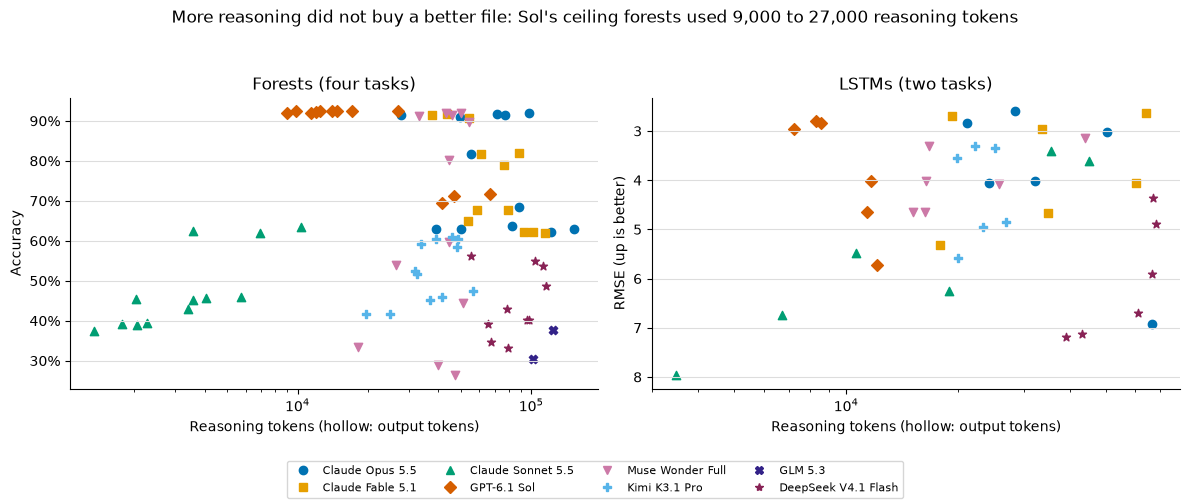

In [38]:
def plot_effort_vs_score(title="Reasoning effort and score"):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    for ax, family in zip(axs, ["forest", "lstm"]):
        for model in MODEL_ORDER:
            s = results[(results.family == family) & (results.model == model) & results.readable]
            for _, r in s.iterrows():
                missing = pd.isna(r.reasoning_tokens)
                x = r.output_tokens if missing else r.reasoning_tokens
                if pd.notna(x) and x > 0:
                    ax.scatter(
                        x,
                        r.score,
                        marker=MARKERS[model],
                        edgecolors=COLORS[model],
                        facecolors="none" if missing else COLORS[model],
                    )
        ax.set_xscale("log")
        ax.set_xlabel("Reasoning tokens (hollow: output tokens)")
        if family == "forest":
            ax.set_ylabel("Accuracy")
            ax.yaxis.set_major_formatter(PercentFormatter(1))
        else:
            ax.set_ylabel("RMSE (up is better)")
            ax.invert_yaxis()
        ax.set_title({"forest": "Forests (four tasks)", "lstm": "LSTMs (two tasks)"}[family])
        ax.xaxis.set_minor_formatter(NullFormatter())
    handles = [
        Line2D([], [], color=COLORS[m], marker=MARKERS[m], ls="", label=MODEL_INFO[m]["label"]) for m in MODEL_ORDER
    ]
    fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.1, 1, 0.94))
    save_figure(fig, "effort_vs_score.png")


plot_effort_vs_score("More reasoning did not buy a better file: Sol's ceiling forests used 9,000 to 27,000 reasoning tokens")

Each marker is one readable reply: reasoning tokens on a log scale across, score up (accuracy for forests; RMSE
for LSTMs with the axis turned over so that up is better).

More reasoning did not buy a better file. Sol's nine ceiling forests used 9,000 to 27,000 reasoning tokens. Opus's
ceiling forests used 28,000 to 98,000 and its failed ones 39,000 to 121,000; Fable's ceiling forests used 38,000 to
54,000 and its failed ones 61,000 to 114,000, so within Fable a long reasoning run went with a worse file. Sonnet
stopped after 1,300 to 10,000 tokens and found the circle in none of its forests. DeepSeek used 55,000 to 116,000 on
forests that scored 33% to 56%. GLM used all 128,000 and returned nothing in 15 of its 18 requests.

Per forest request the median cost was US$0.07 for Sonnet, US$0.05 for DeepSeek, US$0.29 for Sol, US$0.44 for Kimi,
US$0.59 for GLM, US$1.61 for Opus and US$4.23 for Fable; Muse runs on a subscription with no per-request price.
The median forest request took 0.7 minutes for Sonnet, 6 for DeepSeek, 8 for Sol, 11 for Opus, 13 for Muse, 14 for
Fable and 17 for Kimi and GLM. The slowest single request took 51 minutes (Muse on the 600-row task).

Sol's cost includes no subscription quota; it is what the same tokens would cost at OpenAI's published API rates. The
Claude costs are Claude Code's list-price equivalents. The OpenRouter costs are what OpenRouter charged.

In [39]:
print(f"\nCached requests: {len(results)}; total wall hours: {results.wall_minutes.sum(min_count=1) / 60:.2f}")
cost_by_model = results.groupby("model").cost_usd.sum(min_count=1).reindex(MODEL_ORDER)
print("Cost by model (USD):\n", cost_by_model.to_string(na_rep="n/a"))
total_cost = results.cost_usd.sum(min_count=1)
print(f"Total known cost (USD): {total_cost:.2f}" if pd.notna(total_cost) else "Total known cost (USD): n/a")
print(f"Requests with tool events: {int((results.tool_events.fillna(0) > 0).sum())}")


Cached requests: 144; total wall hours: 27.00
Cost by model (USD):
 model
opus        25.041725
fable       66.810396
sonnet       2.499159
sol          5.179454
muse              n/a
kimi         6.875892
glm         10.227222
deepseek     0.889477
Total known cost (USD): 117.52
Requests with tool events: 0


The study made 144 requests. On top of them came 4 retries after transport failures, all GLM through OpenRouter, and
13 open-weight requests that two collection processes sent twice; every attempt is logged in `data/attempts.jsonl`.
The 144 scored replies of the priced models cost US$117.52, 57% of it Fable 5.1 (US$66.81) and 21% Opus (US$25.04);
the duplicates added US$5.64, and Muse ran on a subscription. The pilot cost about US$18 more. Every reply was checked
for tool calls: there were none.

## 10. How the study got here

The study was designed from two small pilot runs; their answers are not used in the results.

- A first quick test on 5 November used an easier forest task (a diagonal boundary and a box, five features, 300 rows)
  and a series with one 12-step cycle, with one Claude Sonnet 5.5 request each. Sonnet's forest scored 71.5% against
  85.0% for a trained forest, and its LSTM RMSE 2.02 against 1.48 for a trained LSTM. A diagonal and a box are close to
  what a tree does anyway, and one cycle is close to what a linear model does, so the tasks could not separate
  recognising a rule from fitting data. The rules and weekly tasks were built to make that difference visible: a circle,
  an exactly-one pattern and a category rule are hard for greedy splits, and an uneven week with promotions needs more
  than one lag.
- On those harder tasks (5 to 7 November) Sonnet wrote forests at 38.5% to 42.5%, Opus at 91.6% and 91.0%, and Fable
  at 91.9% and 59.8%. The two Fable forests differed by 32 points, so the study uses three requests per model per task
  and reports every one. Fable's requests took up to 19 minutes, which set the 90-minute timeout. The pilot also showed
  that choosing the trained LSTM by lowest training error gives a worse model than choosing it on held-out visible
  weeks, so the reference uses held-out weeks.

The full plan was written into `data/PROTOCOL.md` and committed before any main-collection reply was scored.

## 11. Limitations

- The data is synthetic and was designed to have rules a reader can see. Real tables rarely come from three clean rules,
  and the smooth task shows the advantage disappears without one. The result says a model can write a forest when the
  rule is recognisable, not that written forests beat training on real data.
- Three requests per model per task show how much a model varies, not its rate. Sol's 9 of 9 rules-task forests at
  the ceiling still allow a true success rate as low as 72% (one-sided 95% bound); Opus's 5 of 9 is consistent with
  anything from 21% to 86% (95% exact interval).
- Each model ran at one setting, reasoning effort high, with one prompt. A different prompt (for example one that asks
  the model to state the rule before writing the file) or a higher effort could change the results, above all for
  GLM, which ran out of allowance.
- The output allowance was not exactly equal. The open-weight models had a hard 128,000-token limit, while Claude Code
  continued two Claude replies past it. Counting those two as cut off does not change the order of the models.
- The parser was changed twice after some replies had been seen: forests with shared nodes count as readable, and
  split Claude replies are joined. Both changes follow the prompt's own rules, and the notebook reports the results
  both ways; the plan written before the collection is in `data/PROTOCOL.md`.
- The forecasting tasks used one window and one network size. The 8-unit LSTM may be too small to hold a 30-day
  cycle by hand; a larger network, or an input that marks the day of the month, would test whether the writers can
  encode it.
- The references are untuned defaults. A tuned gradient boosting model would score higher on the larger samples, but
  it would not reach the 92.6% ceiling that Sol's forests reach with 200 rows.
- Muse runs on a subscription and reports tokens but not cost, and Sol's cost is an API-rate equivalent, so the costs
  are comparable in tokens more than in dollars.

### What the evidence supports

If the data plausibly follows a short rule, asking a strong model to write the model is worth trying, especially with
few labelled rows: the written forest can be both more accurate than anything trained on the sample and readable. It
should not be trusted from one request. Ask for three files and keep the one with the best score on the visible data,
which here would have delivered a near-ceiling forest from four of the eight models. Sol was the only model that did
not need the check on the rules tasks, and it was also among the cheapest. If the data has no short description, train
the model. For forecasting, a written LSTM is a reasonable small forecaster, but a linear model on the same inputs did
better at no cost; the open question is whether a writer can encode structure, such as a pay cycle, that it does not
spot in one reading.

## 12. How to reproduce

The notebook replays every reply from `data/responses/`, so it runs end to end without an API key or a command line
signed in:

```bash
python -m nbconvert --to notebook --execute --inplace 45_handwritten_forest_lstm.ipynb
```

It needs Python 3.11 or later with numpy, pandas, matplotlib, scipy, scikit-learn and requests. A replay takes a few
minutes; scoring the forests and, on a first run without `data/references/`, training the two reference LSTMs take
most of it.

To collect fresh replies, set `NB45_FRESH=1` before starting Jupyter and remove the reply files to replace. Fresh calls
need the `claude`, `codex` and `muse` command lines signed in and `OPENROUTER_API_KEY` set, and they cost money (see
section 9). `MODELS`, `TASKS` and `N_REPEATS` in the first code cell choose what to run. When a local Langfuse instance
answers at `LANGFUSE_HOST`, each fresh call is also sent there as a trace.

Files:

- `data/responses/<task>/<model>/r<k>.json`: one file per request with the full request (prompt and settings), the
  reply, status, token counts, time and cost.
- `data/attempts.jsonl`: every attempt, including retried transport failures and the duplicated requests described in
  the protocol.
- `data/results.csv`: one row per request with every score used here; `data/summary_*.csv`, `failures.csv` and
  `effort.csv` hold the tables.
- `data/references.json` and `data/references/`: reference scores and the trained LSTM weights.
- `data/PROTOCOL.md`: the pilot, the plan fixed before the main collection, and the collection log with its amendments.
- `data/codex_instructions.txt`: the two-sentence instruction file that replaced Codex's agent instructions.

## 13. Future work and further reading

### Future work

- Real tables published after the models' training cutoffs, with the same forest limits, to see whether the
  advantage survives data that has no clean rule. The smooth task suggests it shrinks to nothing; real data may sit in
  between.
- Ten or more requests per model on the 600-row rules task, to estimate each model's success rate with a usable
  interval and to test whether the visible-data check keeps working when a model's good files are rare.
- A two-step prompt that asks the model first to state the rule it sees and then to write the file. Comparing the
  stated rule with the file would show whether Opus's and Fable's failures are misreads of the data or mistakes in
  writing the trees.
- A forecasting task with a larger LSTM or a day-of-month input, to test whether any writer encodes the pay cycle when
  the network has room for it; and a version that tells the writers the noise carries over from day to day, to see
  whether they then read yesterday's value as the linear model does.
- The same tasks with a code tool allowed, to separate finding the rule (which tool-free writing shows Sol can do)
  from the arithmetic of writing hundreds of thresholds.

### Further reading

Links checked on 9 November 2026.

- [Random Forests](https://doi.org/10.1023/A:1010933404324) (Breiman, 2001). The paper that defined the trained forest
  used as the main forest reference here.
- [Long Short-Term Memory](https://doi.org/10.1162/neco.1997.9.8.1735) (Hochreiter and Schmidhuber, 1997). The
  original LSTM paper, describing the gates that the written weights set by hand.
- [Why do tree-based models still outperform deep learning on typical tabular data?](https://arxiv.org/abs/2207.08815)
  (Grinsztajn et al., 2022). Shows that trees suit irregular boundaries on tabular data; this notebook's smooth task
  is the case where a short rule is missing and trained trees hold up.
- [Tracr: Compiled Transformers as a Laboratory for Interpretability](https://arxiv.org/abs/2301.05062) (Lindner et
  al., 2023). Compiles human-written programs into transformer weights, the program-to-weights step a writer model
  does here by reasoning alone.
- [Forecasting: Principles and Practice, simple methods](https://otexts.com/fpp3/simple-methods.html) (Hyndman and
  Athanasopoulos, 3rd edition). Defines the seasonal naive forecast used here as "same weekday last week".